# Pythia-410m: the collapse law and where subliminal transfer peaks

Every collapse-law result so far lives on `pythia-160m` (the original init and its six
PolyPythias data-/weight-seed siblings). This notebook is the first **width change**: the same
dog focus-teacher recipe (`ep2_lr5e-4_r32a64`, ftseed1) fine-tuned on `pythia-410m`, its
`ex10-20_prefix_n100k` number pool, and ep20 LoRA students on two receivers:

| arm | student base | shared factor with the teacher | design |
|---|---|---|---|
| **same-model** | `pythia-410m` | everything (same init, same data) | pilot 46 cells + ladders (`p410m-same-*`), still draining |
| **cross-seed** | `pythia-410m-seed1` | **none** (full-seed: data *and* weights re-randomised) | pilot 46 + rest 242 = 288-cell strip, ~done |

Both arms use the 160m nonadaptive 8×7 strip universe (56 $(r,\alpha)$ pairs × lr rungs),
placed at $K/K^\ast_{160m}\in[0.02,1.5]$ with $K=\mathrm{lr}\cdot\alpha^{0.561}\cdot r^{-0.085}$ and
the working 160m anchor $K^\ast_{160m}=$ `cl.KSTAR_CALIBRATED` $=8.4\times10^{-4}$. One ftseed per
cell; 40 adapter checkpoints (every 625 steps) with per-checkpoint preference + Pile-KL
trajectories; endpoint pp1 probe.

**Questions.**
1. *Collapse law at 410m.* Does the integrity boundary (Pile-KL on pp1 $>$ `DEAD_KL_CUT`) sit at
   the same $K$ as on 160m, and do the 160m exponents $(b,c)$ still separate alive from dead?
   (§2–§3)
2. *Where does SL peak?* On 160m transfer is humped in $K/K^\ast$ (peaks well below the boundary).
   Where is the 410m hump, how tall is it relative to the base prior, and is it the same dose
   location on both receivers and on both widths? (§4) — plus *when* along training the
   per-run trait peaks (§5).

The single collapse label is the settled one: **dead** = endpoint `kl_base_student` on pp1
$>$ `DEAD_KL_CUT` $=4$ (declared constant). There is no trait-based death label; test
$p(\text{dog})$ is only ever read as a continuous transfer readout. $K^\ast$ estimates use `cl.kstar_logistic` (exponents fixed to the 160m
law) with `cl.kstar_minerr` as the assumption-free cross-check, **per arm** — never pooled across
receivers.

## 0. Setup

In [1]:
from __future__ import annotations

import json
import math
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import parse_param_tag, read_json
from subliminal_learning.analysis.probe_cache import load_probe_cache
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.coherence.probe_io import DEAD_KL_CUT

warnings.filterwarnings("ignore")
pd.set_option("display.width", 230)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

ANIMAL = "dog"
TEACHER = "ep2_lr5e-4_r32a64"          # the focus recipe, ftseed1, on both widths
DATASET = "ex10-20_prefix_n100k"
KSTAR_160 = cl.KSTAR_CALIBRATED        # 8.4e-4: working 160m anchor (cut-4 pooled logistic)
B, Cc = cl.B_LAW, cl.C_LAW

ARMS = {   # label -> (student base dir name, teacher base, width tag)
    "410m same-model":  ("pythia-410m",       "pythia-410m", "410m"),
    "410m cross-seed":  ("pythia-410m-seed1", "pythia-410m", "410m"),
    "160m same-model":  ("pythia-160m",       "pythia-160m", "160m"),
    "160m ds1 (ref)":   ("pythia-160m-data-seed1", "pythia-160m", "160m"),
}
ARM_COLORS = {"410m same-model": "#d9480f", "410m cross-seed": "#1c7ed6",
              "160m same-model": "#f59f00", "160m ds1 (ref)": "#74b816"}


def lineage_dir(student_base: str, teacher_base: str) -> Path:
    return (OUTPUT_ROOT / "students" / ANIMAL / student_base / f"teacher-{teacher_base}"
            / f"{TEACHER}_tseed1" / DATASET)


def krel(tag: str) -> float:
    return cl.k_from_tag(tag) / KSTAR_160


print(f"K*_160m (working anchor) = {KSTAR_160:.3g}   b={B}  c={Cc}   DEAD_KL_CUT={DEAD_KL_CUT}")

K*_160m (working anchor) = 0.00084   b=0.561  c=-0.085   DEAD_KL_CUT=4.0


## 1. Construction + inventory

**Row unit below: one ep20 student run** (cell × ftseed). For the two 410m arms every landed leaf
under the lineage directory is read directly (`preference_eval.json` + `eval/pile_probe.json`; a
`train_diverged.json` counts as dead on both labels) — not just the 288-cell design manifest, so
any ladder cell lands here too. For the 160m references, trait comes from
`cl.load_law_runs` (per-seed `test` p) and Pile-KL from the shared `pile_probe` record cache.
`test_prior` is the **receiver's** own untrained test-prompt $p(\text{dog})$ (410m:
`base_control.json` written next to the cells; 160m: `analysis/base_eval_*`).

The inventory states what has landed versus what the design holds: the 410m same-model arm is
still draining, so its counts are a snapshot (timestamped in the output).

In [2]:
def test_prior_410(student_base: str) -> float:
    d = read_json(lineage_dir(student_base, "pythia-410m") / "base_control.json")
    return float(d["test"]["p_target"])


def test_prior_160(student_base: str) -> float:
    short = {"pythia-160m": "original", "pythia-160m-data-seed1": "ds1"}[student_base]
    f = OUTPUT_ROOT / "analysis" / f"base_eval_{short}_animal_preference_test.json"
    return float(np.mean(read_json(f)[ANIMAL]["p_per_prompt"]))


def load_410(student_base: str) -> pd.DataFrame:
    rows = []
    for cell in sorted(lineage_dir(student_base, "pythia-410m").glob("ep20_*")):
        pt = parse_param_tag(cell.name)
        for leaf in sorted(cell.glob("ftseed*")):
            rec = dict(student_tag=cell.name, seed=int(leaf.name.removeprefix("ftseed")),
                       lr=pt["lr"], alpha=pt["alpha"], rank=pt["rank"], leaf=str(leaf))
            if (leaf / "train_diverged.json").exists():
                rows.append({**rec, "test": 0.0, "kl": math.inf, "diverged": True}); continue
            pe, pp = leaf / "preference_eval.json", leaf / "eval" / "pile_probe.json"
            if not (pe.exists() and pp.exists()):
                rows.append({**rec, "test": np.nan, "kl": np.nan, "diverged": False}); continue
            e, p = read_json(pe), read_json(pp)
            kl = p.get("kl_base_student")
            rows.append({**rec, "test": float(e["sets"]["test"]["p_target"]),
                         "off_topic": float(e["sets"]["off_topic"]["p_target"]),
                         "kl": math.inf if kl is None else float(kl),
                         "delta_ce": p.get("delta_ce"), "diverged": False})
    return pd.DataFrame(rows)


def load_160(student_base: str) -> pd.DataFrame:
    _, r = cl.load_law_runs(OUTPUT_ROOT, animal=ANIMAL, numbers_base="pythia-160m", dataset=DATASET,
                            epochs=20, lineages=[("focus", TEACHER, student_base)])
    if not len(r):
        return r
    r = r[["student_tag", "seed", "lr", "alpha", "rank", "test"]].copy()
    r["leaf"] = [str(lineage_dir(student_base, "pythia-160m") / t / f"ftseed{s}")
                 for t, s in zip(r.student_tag, r.seed)]
    rel = [str(Path(p).relative_to(OUTPUT_ROOT)) for p in r.leaf]
    pc = load_probe_cache(OUTPUT_ROOT, rel, refresh=True, pool_version="pp1")
    pc = pc.assign(leaf=[str(OUTPUT_ROOT / p) for p in pc.run_path])[["leaf", "kl", "delta_ce"]]
    r = r.merge(pc, on="leaf", how="left")
    r["diverged"] = np.isinf(r.kl)
    return r


frames = {}
for arm, (sb, tb, width) in ARMS.items():
    df = load_410(sb) if width == "410m" else load_160(sb)
    prior = test_prior_410(sb) if width == "410m" else test_prior_160(sb)
    df["arm"], df["width"], df["student_base"], df["test_prior"] = arm, width, sb, prior
    frames[arm] = df
runs = pd.concat(frames.values(), ignore_index=True)
runs["K"] = cl.K_of(runs.lr, runs.alpha, runs["rank"])
runs["K_rel"] = runs.K / KSTAR_160
runs["landed"] = runs.test.notna()
runs["dead_kl"] = runs.kl > DEAD_KL_CUT
runs["transfer"] = runs.test / runs.test_prior          # test p(dog) in units of the receiver's prior
runs["probed"] = runs.kl.notna()

import datetime as _dt
print("snapshot:", _dt.datetime.now().strftime("%Y-%m-%d %H:%M"))
inv = (runs.groupby("arm").agg(student_base=("student_base", "first"), test_prior=("test_prior", "first"),
                               cells=("student_tag", "nunique"), runs=("leaf", "size"),
                               landed=("landed", "sum"), kl_probed=("probed", "sum"),
                               ftseeds=("seed", "nunique"),
                               K_rel_min=("K_rel", "min"), K_rel_max=("K_rel", "max"))
         .loc[list(ARMS)])
design_n = len(read_json(ROOT / "run_logs/p410m/strip_cells.json")["rows"])
inv["design_cells"] = [design_n, design_n, np.nan, np.nan]
display(inv.round(4))
print(f"410m strip design = {design_n} cells (56 (r,alpha) pairs x 4-6 lr rungs); 'cells' counts directories that exist, "
      f"'landed' = endpoint eval written.")
runs = runs[runs.landed].copy()

pile_probe cache: 0 rows of 29368 cached (0 added, 0 refreshed, 312 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1520 rows of 29368 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)
snapshot: 2026-08-22 02:16


,student_base,test_prior,cells,runs,landed,kl_probed,ftseeds,K_rel_min,K_rel_max,design_cells
arm,,,,,,,,,,
410m same-model,pythia-410m,0.0229,168,168,168,168,1,0.0210,1.3944,288.0
410m cross-seed,pythia-410m-seed1,0.0103,288,288,288,288,1,0.0205,1.4790,288.0
160m same-model,pythia-160m,0.0096,229,312,312,0,2,0.0091,24.5481,NaN
160m ds1 (ref),pythia-160m-data-seed1,0.0133,598,1520,1520,1520,6,0.0086,18.1078,NaN


410m strip design = 288 cells (56 (r,alpha) pairs x 4-6 lr rungs); 'cells' counts directories that exist, 'landed' = endpoint eval written.


## 2. Fates on the 160m dose axis

Both panels put every landed run at its $K/K^\ast_{160m}$ (log). Left: endpoint Pile-KL on the
pp1 pool (the integrity readout; rule = `DEAD_KL_CUT`). Right: test $p(\text{dog})$ in units of
the receiver's prior (log; continuous readout, no cut). Row unit: one run. Colour = arm;
the 160m references are drawn lighter/smaller. The vertical rule is the 160m boundary.

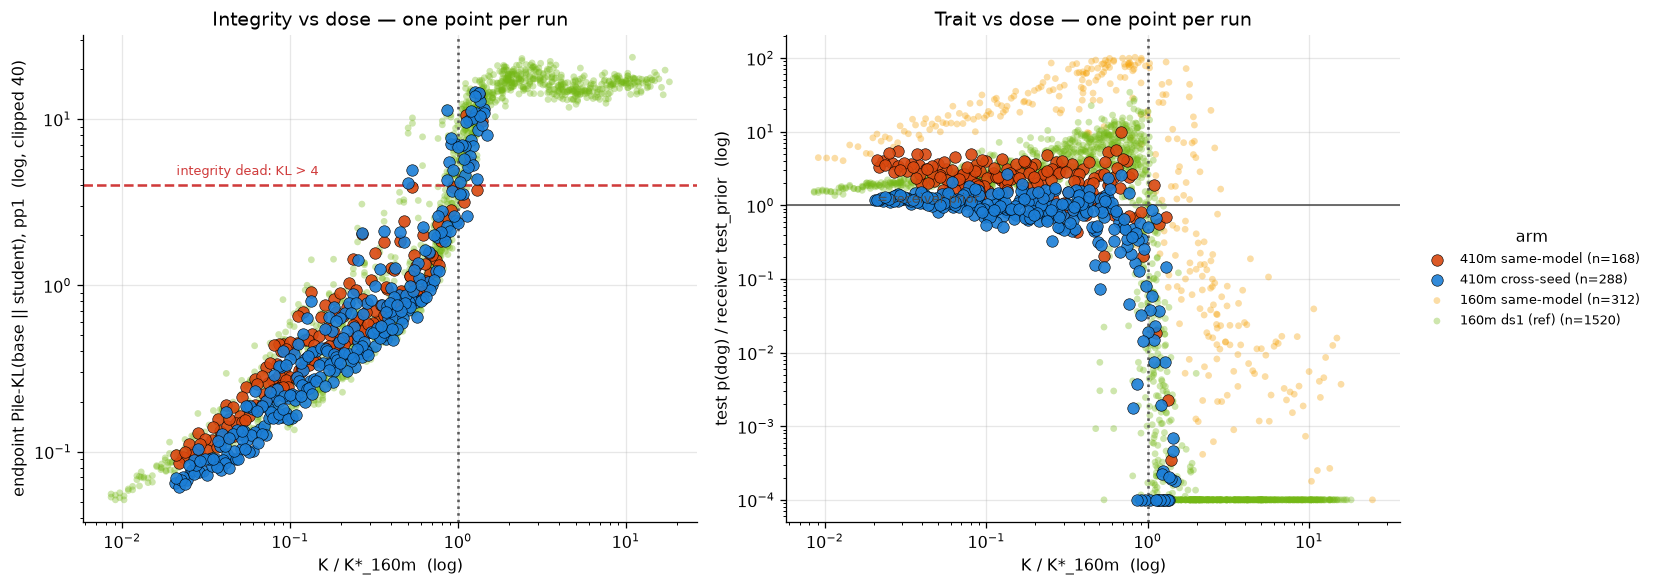

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.2))
for arm in ARMS:
    sub = runs[runs.arm == arm]
    big = sub.width.iloc[0] == "410m" if len(sub) else True
    kw = dict(s=52 if big else 18, alpha=0.9 if big else 0.35, color=ARM_COLORS[arm],
              edgecolor="k" if big else "none", lw=0.4, label=f"{arm} (n={len(sub)})", zorder=3 if big else 2)
    ax1.scatter(sub.K_rel, sub.kl.clip(upper=40), **kw)
    ax2.scatter(sub.K_rel, sub.transfer.clip(lower=1e-4), **kw)
for ax in (ax1, ax2):
    ax.axvline(1.0, color="0.35", ls=":", lw=1.6)
    ax.set(xscale="log", yscale="log", xlabel="K / K*_160m  (log)")
ax1.axhline(DEAD_KL_CUT, color="#d03b3b", ls="--", lw=1.6)
ax1.text(0.021, DEAD_KL_CUT * 1.15, f"integrity dead: KL > {DEAD_KL_CUT:g}", color="#d03b3b", fontsize=8)
ax1.set(ylabel="endpoint Pile-KL(base || student), pp1  (log, clipped 40)",
        title="Integrity vs dose — one point per run")
ax2.axhline(1.0, color="0.3", ls="-", lw=1.0)
ax2.text(0.021, 1.08, "= receiver prior", color="0.3", fontsize=8)
ax2.set(ylabel="test p(dog) / receiver test_prior  (log)",
        title="Trait vs dose — one point per run")
aplots.right_legend(ax2, title="arm", fontsize=8)
plt.tight_layout(); plt.show()

### 2b. $K^\ast$ per arm, both labels

`cl.kstar_logistic` on the arm's own runs with $(b,c)$ fixed to the 160m law; `se_log` is the
cluster-robust delta-method SE of $\log K^\ast$, `err` the misclassification at the 0.5 rule,
`minerr` the assumption-free cut. The ratio column is $K^\ast_{arm}/K^\ast_{160m}$. An arm whose
label has no variation (nothing dead yet) is reported as *not bracketed*. Row unit: one arm ×
label.

In [4]:
def fit_rows(df: pd.DataFrame) -> list[dict]:
    out = []
    for arm, sub in df.groupby("arm", sort=False):
        for lab in ("dead_kl",):
            d = sub.dropna(subset=["kl"] if lab == "dead_kl" else ["test"]).assign(collapsed=lambda x: x[lab].astype(int))
            row = {"arm": arm, "label": lab, "n": len(d), "n_dead": int(d.collapsed.sum())}
            if d.collapsed.nunique() < 2:
                row["note"] = "not bracketed"; out.append(row); continue
            f = cl.kstar_logistic(d, B, Cc); m = cl.kstar_minerr(d, B, Cc)
            row.update(kstar=f["kstar"], ratio_vs_160m=f["kstar"] / KSTAR_160, se_log=f["se_log"],
                       ci_lo=f["kstar"] * np.exp(-1.96 * f["se_log"]) / KSTAR_160,
                       ci_hi=f["kstar"] * np.exp(1.96 * f["se_log"]) / KSTAR_160,
                       slope=f["slope"], err=f["err"], minerr_ratio=m["kstar"] / KSTAR_160, minerr_err=m["err"])
            out.append(row)
    return out


kfits = pd.DataFrame(fit_rows(runs)).set_index(["arm", "label"])
kfits = kfits.loc[[(a, l) for a in ARMS for l in ("dead_kl",) if (a, l) in kfits.index]]
display(kfits.round(3))
KSTAR_410 = {a: kfits.loc[(a, "dead_kl"), "kstar"] for a in ("410m same-model", "410m cross-seed")
             if (a, "dead_kl") in kfits.index and pd.notna(kfits.loc[(a, "dead_kl")].get("kstar", np.nan))}
for a, k in KSTAR_410.items():
    print(f"{a:18s} integrity K* = {k:.3g}  = {k / KSTAR_160:.2f} x K*_160m")

,,n,n_dead,kstar,ratio_vs_160m,se_log,ci_lo,ci_hi,slope,err,minerr_ratio,minerr_err,note
arm,label,,,,,,,,,,,,
410m same-model,dead_kl,168,4,0.001,1.155,0.080,0.988,1.350,12.278,0.012,1.102,0.006,NaN
410m cross-seed,dead_kl,288,36,0.001,0.918,0.041,0.846,0.996,7.399,0.045,0.847,0.038,NaN
160m same-model,dead_kl,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not bracketed
160m ds1 (ref),dead_kl,1520,652,0.001,0.932,0.019,0.898,0.966,11.848,0.033,0.963,0.032,NaN


410m same-model    integrity K* = 0.00097  = 1.16 x K*_160m
410m cross-seed    integrity K* = 0.000771  = 0.92 x K*_160m


### 2c. $K^\ast$ along the trajectory — refit at every checkpoint

Same estimator as §2b, but the labels are taken from the per-checkpoint files instead of the
endpoint: at each checkpoint step $s$ a run is *dead* if `pile_kl_traj` KL$(s) >$
`DEAD_KL_CUT`. At each checkpoint the full law
$\mathrm{logit}\,P(\text{dead}) = \beta_0+\beta_{lr}\ln lr+\beta_\alpha\ln\alpha+\beta_r\ln r$ is **refit from scratch**
(`cl.fit_collapse_law`, cluster-robust by cell), giving the exponents $b=\beta_\alpha/\beta_{lr}$,
$c=\beta_r/\beta_{lr}$ and the boundary $K^\ast(s)=\exp(-\beta_0/\beta_{lr})$ in the units of that
checkpoint's own $lr\cdot\alpha^{b}\cdot r^{c}$. Fixed-exponent $K^\ast$ values are kept for reference at the 160m **strip** exponents
($b=0.613, c=-0.109$; orig→ds1, KL label) and at the placement-era `cl.B_LAW` pair. The
reference rules in the plot are the strip's, not `B_LAW`. A free fit needs $\ge 8$ dead and $\ge 8$ alive runs. The plot shows $K^\ast(s)/K^\ast_{160m}$ (log) with the delta-method 95% band
vs step fraction, one line per arm. Row unit of the table: one arm × checkpoint
(every 5th checkpoint shown; the plot uses all). A falling curve means the boundary keeps
marching inward as training proceeds (the ep20 endpoint is the *most* restrictive label); a flat
curve means fate is decided early.


runs with trajectories: {'410m cross-seed': 288, '410m same-model': 168}


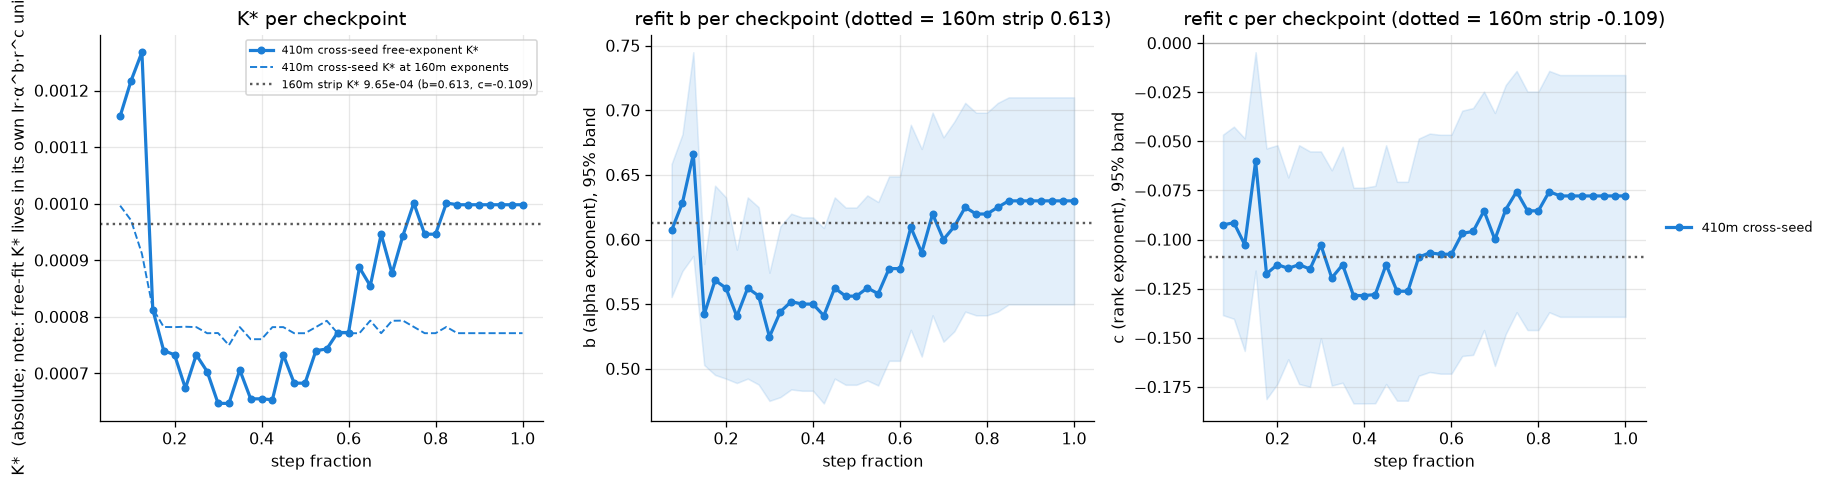

n  n_dead    kstar        b        c  kstar_strip_exps  kstar_fixed                           note
arm             frac                                                                                                       
410m cross-seed 0.025  288       0      NaN      NaN      NaN               NaN          NaN  too few deaths for a free fit
                0.050  288       2      NaN      NaN      NaN           0.00145      0.00142  too few deaths for a free fit
                0.075  288      17  0.00115  0.60698 -0.09256           0.00114      0.00100                            NaN
                0.100  288      19  0.00122  0.62849 -0.09144           0.00110      0.00097                            NaN
                0.125  288      24  0.00127  0.66612 -0.10261           0.00103      0.00091                            NaN
                0.150  288      32  0.00081  0.54200 -0.06021           0.00092      0.00081                            NaN
                0.250  288      35  0.00073  0.56248 -0.11278           0.00088      0.00078                            NaN
                0.375  288      37  0.00066  0.55006 -0.12852           0.00086      0.00076                            NaN
                0.500  288      36  0.00068  0.55621 -0.12632           0.00087      0.00077                            NaN
                0.625  288      36  0.00089  0.60943 -0.09685           0.00087      0.00077                            NaN
                0.750  288      35  0.00100  0.62496 -0.07561           0.00088      0.00078                            NaN
                0.875  288      36  0.00100  0.62991 -0.07781           0.00087      0.00077                            NaN
                1.000  288      36  0.00100  0.62991 -0.07781           0.00087      0.00077                            NaN
410m same-model 0.025  168       0      NaN      NaN      NaN               NaN          NaN  too few deaths for a free fit
                0.050  168       1      NaN      NaN      NaN           0.00141      0.00119  too few deaths for a free fit
                0.075  168       2      NaN      NaN      NaN           0.00130      0.00117  too few deaths for a free fit
                0.100  168       2      NaN      NaN      NaN           0.00130      0.00117  too few deaths for a free fit
                0.125  168       4      NaN      NaN      NaN           0.00112      0.00097  too few deaths for a free fit
                0.150  168       4      NaN      NaN      NaN           0.00112      0.00097  too few deaths for a free fit
                0.250  168       7      NaN      NaN      NaN           0.00094      0.00083  too few deaths for a free fit
                0.375  168       5      NaN      NaN      NaN           0.00101      0.00093  too few deaths for a free fit
                0.500  168       4      NaN      NaN      NaN           0.00112      0.00097  too few deaths for a free fit
                0.625  168       5      NaN      NaN      NaN           0.00101      0.00093  too few deaths for a free fit
                0.750  168       5      NaN      NaN      NaN           0.00101      0.00093  too few deaths for a free fit
                0.875  168       4      NaN      NaN      NaN           0.00110      0.00097  too few deaths for a free fit
                1.000  168       4      NaN      NaN      NaN           0.00110      0.00097  too few deaths for a free fit

In [5]:
def traj_labels(leaf: str, prior: float) -> pd.DataFrame | None:
    g = Path(leaf) / "eval" / "pile_kl_traj.json"
    if not g.exists():
        return None
    kp = read_json(g)["points"]
    ks = np.array([q["step"] for q in kp]); kl = np.array([q["kl_base_adapted"] for q in kp])
    return pd.DataFrame({"frac": ks / ks.max(), "dead_kl": kl > DEAD_KL_CUT})


import warnings as _w; _w.simplefilter('ignore')
rows = []
for arm in ("410m same-model", "410m cross-seed"):
    sub = runs[runs.arm == arm]
    for _, r in sub.iterrows():
        t = traj_labels(r.leaf, r.test_prior)
        if t is None:
            if r.diverged:   # diverged runs: dead on both labels at every checkpoint
                t = pd.DataFrame({"frac": np.linspace(0.025, 1, 40), "dead_kl": True})
            else:
                continue
        rows.append(t.assign(arm=arm, lr=r.lr, alpha=r.alpha, rank=r["rank"], student_tag=r.student_tag, leaf=r.leaf))
TR = pd.concat(rows, ignore_index=True)
TR["frac"] = TR.frac.round(3)
TR = TR.drop_duplicates(["leaf", "frac"], keep="last")   # the final step can be written twice
print("runs with trajectories:", TR.groupby("arm").leaf.nunique().to_dict())

# 160m reference = the calibrated 160m strip (orig -> ds1, KL > 4 label; docs/results/collapse_law.md §2)
B_STRIP, C_STRIP, KSTAR_STRIP = 0.613, -0.109, 9.65e-4
kt = []
for (arm, frac), g in TR.groupby(["arm", "frac"]):
    d = g.assign(collapsed=g["dead_kl"].astype(int))
    row = dict(arm=arm, frac=frac, n=len(d), n_dead=int(d.collapsed.sum()))
    if d.collapsed.nunique() == 2:
        row["kstar_fixed"] = cl.kstar_logistic(d, B, Cc)["kstar"]          # placement-era exponents (cl.B_LAW)
        row["kstar_strip_exps"] = cl.kstar_logistic(d, B_STRIP, C_STRIP)["kstar"]   # 160m strip exponents
    if d.collapsed.sum() >= 8 and (len(d) - d.collapsed.sum()) >= 8:
        try:
            f = cl.fit_collapse_law(d)                                        # free (b, c) at this checkpoint
            b0, bl = f.params[0], f.params[1]
            row.update(b=f.b, c=f.c, b_lo=f.b_ci[0], b_hi=f.b_ci[1], c_lo=f.c_ci[0], c_hi=f.c_ci[1],
                       kstar=float(np.exp(-b0 / bl)), converged=f.converged)   # boundary of lr·α^b·r^c
        except Exception as ex:
            row["note"] = f"free fit failed: {ex}"
    else:
        row["note"] = "too few deaths for a free fit"
    kt.append(row)
kt = pd.DataFrame(kt)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for arm, g in kt.dropna(subset=["kstar"]).groupby("arm"):
    g = g.sort_values("frac"); col = ARM_COLORS[arm]
    axes[0].plot(g.frac, g.kstar, "-o", color=col, lw=2, ms=4, label=f"{arm} free-exponent K*")
    axes[0].plot(g.frac, g.kstar_fixed, "--", color=col, lw=1.2, label=f"{arm} K* at 160m exponents")
    axes[1].plot(g.frac, g.b, "-o", color=col, lw=2, ms=4, label=arm); axes[1].fill_between(g.frac, g.b_lo, g.b_hi, color=col, alpha=0.12)
    axes[2].plot(g.frac, g.c, "-o", color=col, lw=2, ms=4, label=arm); axes[2].fill_between(g.frac, g.c_lo, g.c_hi, color=col, alpha=0.12)
axes[0].axhline(KSTAR_STRIP, color="0.35", ls=":", lw=1.5, label=f"160m strip K* {KSTAR_STRIP:.2e} (b=0.613, c=-0.109)")
axes[1].axhline(B_STRIP, color="0.35", ls=":", lw=1.5); axes[2].axhline(C_STRIP, color="0.35", ls=":", lw=1.5); axes[2].axhline(0, color="0.7", lw=0.8)
axes[0].set(xlabel="step fraction", ylabel="K*  (absolute; note: free-fit K* lives in its own lr·α^b·r^c units)", title="K* per checkpoint")
axes[1].set(xlabel="step fraction", ylabel="b (alpha exponent), 95% band", title="refit b per checkpoint (dotted = 160m strip 0.613)")
axes[2].set(xlabel="step fraction", ylabel="c (rank exponent), 95% band", title="refit c per checkpoint (dotted = 160m strip -0.109)")
aplots.right_legend(axes[2], fontsize=8); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

show = kt[(kt.frac <= 0.15) | np.isclose(kt.frac * 40 % 5, 0) | np.isclose(kt.frac, 1.0)]
display(show.set_index(["arm", "frac"])[["n", "n_dead", "kstar", "b", "c", "kstar_strip_exps", "kstar_fixed", "note"]].round(5))


### 2d. The dose law at 410m — endpoint and along the trajectory

Label-free leg of the mechanism: the realized update size $dw = \overline{s\,\|BA\|_F/\|W_0\|_F}$
(module mean, $s=\alpha/r$; `eval/adapter_norms.json`, slim harvest) regressed on the HPs,
$\log dw = a\log lr + b'\log\alpha + c'\log r$ (OLS, cluster-robust by cell). The 160m strip gives
$dw \propto lr^{1.05}\alpha^{0.69}r^{-0.24}$ and the implied boundary exponents $b'/a$, $c'/a$.
Also reported: $\hat\theta$, the $dw$ cut that best separates dead (KL $>$ cut) from alive (160m:
0.122). The trajectory panel refits the same regression on $dw(s)$ read from
`eval/adapter_norms_traj.json` at each checkpoint, and checks monotonicity (max/endpoint of $dw$).
Row unit: one run (endpoint), one arm × checkpoint (trajectory). Counts state what has landed
(the harvest is a CPU-lane queue, `p410m-norms-traj`).


endpoint norm records: {'410m cross-seed': '108/288', '410m same-model': '61/168'}


,n,a_lr,b_alpha,c_rank,implied_b,implied_c,R2,theta_hat,theta_err,n_dead
arm,,,,,,,,,,
410m cross-seed,108.0,0.924,0.736,-0.322,0.796,-0.348,0.981,0.134,0.046,11.0
410m same-model,61.0,1.011,0.764,-0.305,0.756,-0.302,0.983,0.193,0.049,2.0
160m strip (ref),NaN,1.050,0.690,-0.240,0.657,-0.229,NaN,0.122,NaN,NaN


dw max/endpoint per run (1.0 = monotone):


,count,50%,99%,max
arm,,,,
410m cross-seed,102.0,1.0,1.0,1.0
410m same-model,59.0,1.0,1.0,1.0


n      a  implied_b  implied_c
arm             frac                                  
410m cross-seed 0.2   102  0.892      0.886     -0.429
                0.4   102  0.930      0.827     -0.371
                0.6   102  0.928      0.804     -0.354
                0.8   102  0.922      0.797     -0.351
                1.0   102  0.921      0.796     -0.351
410m same-model 0.2    59  1.032      0.820     -0.355
                0.4    59  1.052      0.777     -0.310
                0.6    59  1.032      0.760     -0.300
                0.8    59  1.016      0.756     -0.302
                1.0    59  1.013      0.755     -0.302

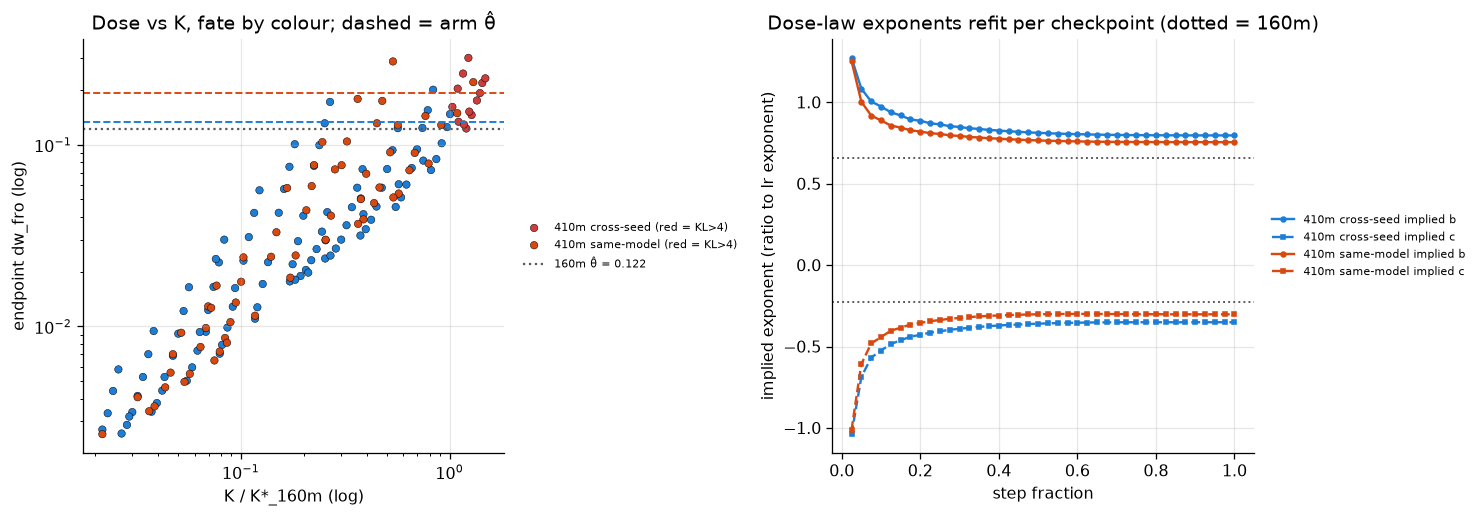

In [6]:
import statsmodels.formula.api as smf

def _dw_fro(mods, s):
    v = [s * m["B_Afinal_fro"] / m["W0_fro"] for m in mods if m.get("W0_fro")]
    return float(np.mean(v)) if v else np.nan

def norms_end(leaf):
    f = Path(leaf) / "eval" / "adapter_norms.json"
    if not f.exists():
        return np.nan
    r = read_json(f); return _dw_fro(r["modules"], r["alpha"] / r["rank"])

def norms_traj(leaf):
    f = Path(leaf) / "eval" / "adapter_norms_traj.json"
    if not f.exists():
        return None
    r = read_json(f); s = r["alpha"] / r["rank"]
    pts = sorted(r["points"], key=lambda q: q["step"])
    return pd.DataFrame({"step": [q["step"] for q in pts], "dw": [_dw_fro(q["modules"], s) for q in pts]})

r4 = runs[runs.width == "410m"].copy()
r4["dw_fro"] = [norms_end(l) for l in r4.leaf]
r4["lln"], r4["aln"], r4["rln"] = np.log(r4.lr), np.log(r4.alpha), np.log(r4["rank"])
print("endpoint norm records:", r4.groupby("arm").dw_fro.apply(lambda x: f"{x.notna().sum()}/{len(x)}").to_dict())

REF160 = dict(a=1.05, b=0.69, c=-0.24, theta=0.122)   # docs/results/collapse_law.md §4
rows = []
for arm, g in r4.dropna(subset=["dw_fro"]).groupby("arm"):
    g = g[np.isfinite(np.log(g.dw_fro))]
    if len(g) < 12:
        rows.append(dict(arm=arm, n=len(g), note="too few records")); continue
    o = smf.ols("np.log(dw_fro) ~ lln + aln + rln", g).fit(cov_type="cluster", cov_kwds={"groups": g.student_tag})
    a, b, c = o.params["lln"], o.params["aln"], o.params["rln"]
    row = dict(arm=arm, n=len(g), a_lr=a, b_alpha=b, c_rank=c, implied_b=b / a, implied_c=c / a, R2=o.rsquared)
    gk = g.dropna(subset=["kl"])
    if gk.dead_kl.nunique() == 2:
        cuts = np.sort(gk.dw_fro.unique()); errs = [((gk.dw_fro >= t) != gk.dead_kl).mean() for t in cuts]
        row.update(theta_hat=float(cuts[int(np.argmin(errs))]), theta_err=float(min(errs)), n_dead=int(gk.dead_kl.sum()))
    rows.append(row)
rows.append(dict(arm="160m strip (ref)", a_lr=REF160["a"], b_alpha=REF160["b"], c_rank=REF160["c"],
                 implied_b=REF160["b"] / REF160["a"], implied_c=REF160["c"] / REF160["a"], theta_hat=REF160["theta"]))
dose = pd.DataFrame(rows).set_index("arm"); display(dose.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for arm, g in r4.dropna(subset=["dw_fro"]).groupby("arm"):
    axes[0].scatter(g.K_rel, g.dw_fro, c=np.where(g.dead_kl, "#d03b3b", ARM_COLORS[arm]), s=22, edgecolor="k", lw=0.3,
                    label=f"{arm} (red = KL>{DEAD_KL_CUT:g})")
    if arm in dose.index and "theta_hat" in dose and pd.notna(dose.loc[arm].get("theta_hat", np.nan)):
        axes[0].axhline(dose.loc[arm, "theta_hat"], color=ARM_COLORS[arm], ls="--", lw=1.2)
axes[0].axhline(REF160["theta"], color="0.35", ls=":", lw=1.4, label="160m θ̂ = 0.122")
axes[0].set(xscale="log", yscale="log", xlabel="K / K*_160m (log)", ylabel="endpoint dw_fro (log)", title="Dose vs K, fate by colour; dashed = arm θ̂")
aplots.right_legend(axes[0], fontsize=7)

# trajectory: exponents and monotonicity per checkpoint
tr = []
for _, r in r4.iterrows():
    t = norms_traj(r.leaf)
    if t is None: continue
    t["frac"] = (t.step / t.step.max()).round(3)
    tr.append(t.assign(arm=r.arm, lln=r.lln, aln=r.aln, rln=r.rln, student_tag=r.student_tag, leaf=r.leaf))
TRN = pd.concat(tr, ignore_index=True) if tr else pd.DataFrame()
if len(TRN):
    mono = TRN.groupby(["arm", "leaf"]).apply(lambda d: d.dw.max() / d.dw.iloc[-1]).groupby("arm").describe(percentiles=[.5, .99])[["count", "50%", "99%", "max"]]
    print("dw max/endpoint per run (1.0 = monotone):"); display(mono.round(4))
    ex = []
    for (arm, frac), g in TRN.groupby(["arm", "frac"]):
        g = g[np.isfinite(np.log(g.dw))]
        if len(g) < 12: continue
        o = smf.ols("np.log(dw) ~ lln + aln + rln", g).fit()
        ex.append(dict(arm=arm, frac=frac, n=len(g), a=o.params["lln"], implied_b=o.params["aln"] / o.params["lln"], implied_c=o.params["rln"] / o.params["lln"]))
    ex = pd.DataFrame(ex)
    for arm, g in ex.groupby("arm"):
        axes[1].plot(g.frac, g.implied_b, "-o", color=ARM_COLORS[arm], ms=3, label=f"{arm} implied b")
        axes[1].plot(g.frac, g.implied_c, "--s", color=ARM_COLORS[arm], ms=3, label=f"{arm} implied c")
    axes[1].axhline(REF160["b"] / REF160["a"], color="0.35", ls=":", lw=1.2); axes[1].axhline(REF160["c"] / REF160["a"], color="0.35", ls=":", lw=1.2)
    axes[1].set(xlabel="step fraction", ylabel="implied exponent (ratio to lr exponent)", title="Dose-law exponents refit per checkpoint (dotted = 160m)")
    aplots.right_legend(axes[1], fontsize=7)
    display(ex[np.isclose(ex.frac * 40 % 8, 0) | np.isclose(ex.frac, 1.0)].set_index(["arm", "frac"]).round(3))
plt.tight_layout(); plt.show()


## 3. Does the 160m law hold at 410m?

Two checks, on the arm with enough deaths (the cross-seed strip; the same-model arm is shown
when it has ≥ 8 deaths).

**3a. Fate heatmap in the strip's own coordinates.** Facets = rank, x = $\alpha$, y = lr; cell
colour = integrity fate (white = alive, red = dead, grey = not landed). Overlaid: the 160m
boundary $\mathrm{lr}^\ast(\alpha,r)=K^\ast_{160m}\,\alpha^{-b}r^{-c}$ (dotted) and the arm's own
refit $K^\ast$ (solid). If the law holds the dead cells sit above both lines in every facet
and the lines are parallel to the alive/dead edge.

**3b. Free exponent refit.** `cl.fit_collapse_law` refits $(b,c)$ as coefficient ratios on the
410m runs alone (cluster-robust delta-method CIs). Compare with the 160m law's $b=0.561$,
$c=-0.085$.

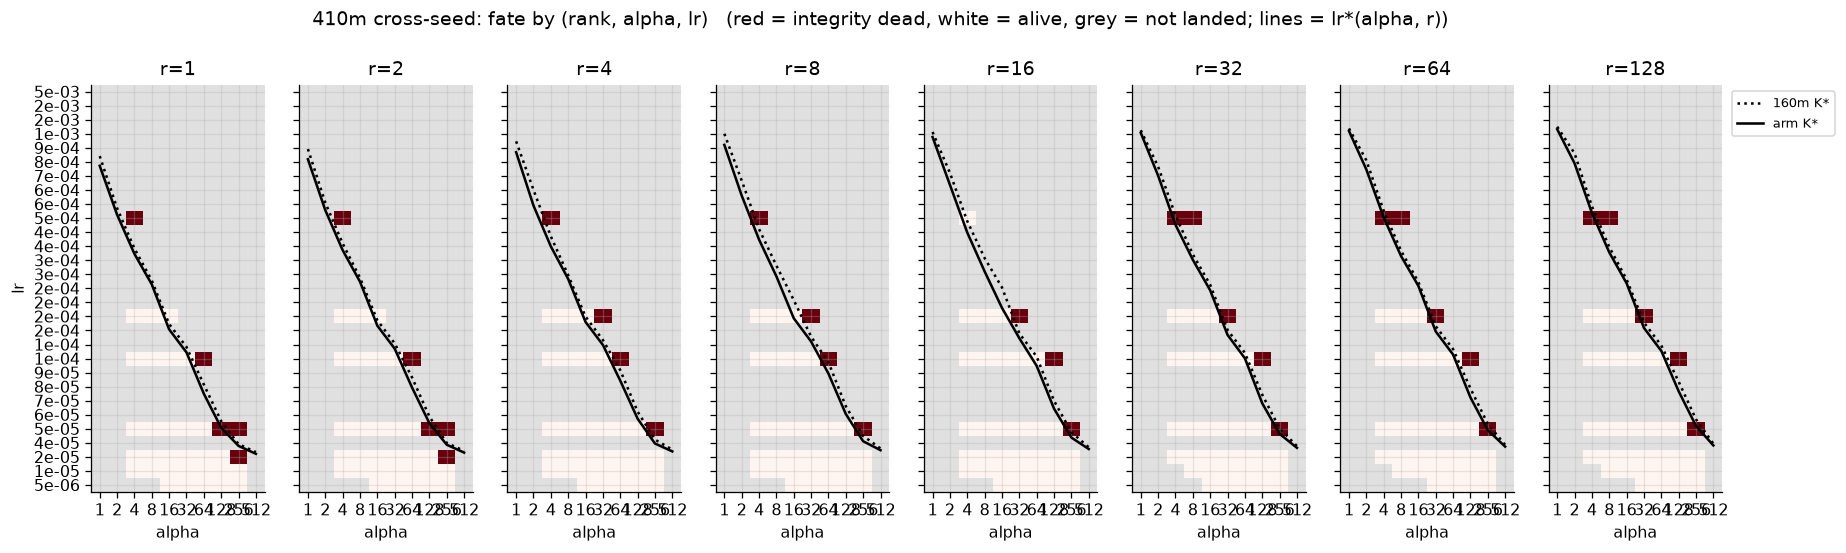

410m same-model: only 4 integrity deaths so far -- heatmap deferred


In [7]:
LR_RUNGS = sorted(runs.lr.unique())
ALPHAS = sorted(runs.alpha.unique()); RANKS = sorted(runs["rank"].unique())

def fate_heatmap(df: pd.DataFrame, kstar_arm: float | None, title: str):
    fig, axes = plt.subplots(1, len(RANKS), figsize=(2.1 * len(RANKS) + 1.5, 4.6), sharey=True)
    for ax, r in zip(axes, RANKS):
        sub = df[df["rank"] == r]
        grid = np.full((len(LR_RUNGS), len(ALPHAS)), np.nan)
        for row in sub.itertuples():
            grid[LR_RUNGS.index(row.lr), ALPHAS.index(row.alpha)] = float(row.dead_kl)
        cmap = plt.get_cmap("Reds").copy(); cmap.set_bad("0.88")
        ax.imshow(np.ma.masked_invalid(grid), cmap=cmap, vmin=0, vmax=1, origin="lower", aspect="auto")
        xs = np.arange(len(ALPHAS))
        for k, ls, lab in ((KSTAR_160, ":", "160m K*"), (kstar_arm, "-", "arm K*")):
            if k is None: continue
            lr_star = k * np.asarray(ALPHAS, float) ** (-B) * r ** (-Cc)
            # position on the categorical lr axis via log interpolation between rungs
            ypos = np.interp(np.log(lr_star), np.log(LR_RUNGS), np.arange(len(LR_RUNGS)))
            ax.plot(xs, ypos, color="k", ls=ls, lw=1.6, label=lab)
        ax.set(title=f"r={r}", xticks=xs, xticklabels=ALPHAS, xlabel="alpha")
        ax.set_ylim(-0.5, len(LR_RUNGS) - 0.5)
    axes[0].set(yticks=np.arange(len(LR_RUNGS)), yticklabels=[f"{v:.0e}" for v in LR_RUNGS], ylabel="lr")
    axes[-1].legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=8)
    fig.suptitle(title + "   (red = integrity dead, white = alive, grey = not landed; lines = lr*(alpha, r))", y=1.02)
    plt.show()


for arm in ("410m cross-seed", "410m same-model"):
    sub = runs[(runs.arm == arm) & runs.probed]
    if sub.dead_kl.sum() >= 8:
        fate_heatmap(sub, KSTAR_410.get(arm), f"{arm}: fate by (rank, alpha, lr)")
    else:
        print(f"{arm}: only {int(sub.dead_kl.sum())} integrity deaths so far -- heatmap deferred")

In [8]:
rows = []
for arm in ("410m cross-seed", "410m same-model"):
    for lab in ("dead_kl",):
        d = runs[(runs.arm == arm) & runs.probed].assign(collapsed=lambda x: x[lab].astype(int))
        if d.collapsed.sum() < 8:
            rows.append({"arm": arm, "label": lab, "n_dead": int(d.collapsed.sum()), "note": "too few deaths"}); continue
        try:
            f = cl.fit_collapse_law(d)
            rows.append({"arm": arm, "label": lab, "n": f.n_runs, "n_dead": f.n_dead,
                         "b": f.b, "b_ci": tuple(np.round(f.b_ci, 3)), "c": f.c, "c_ci": tuple(np.round(f.c_ci, 3)),
                         "converged": f.converged})
        except Exception as ex:
            rows.append({"arm": arm, "label": lab, "note": f"fit failed: {ex}"})
free = pd.DataFrame(rows)
print(f"160m law: b = {B}, c = {Cc}   (alpha exponent; rank exponent, negative = protective)")
display(free.round(3))

160m law: b = 0.561, c = -0.085   (alpha exponent; rank exponent, negative = protective)


,arm,label,n,n_dead,b,b_ci,c,c_ci,converged,note
0,410m cross-seed,dead_kl,288.0,36,0.63,"(0.55, 0.71)",-0.078,"(-0.139, -0.016)",True,NaN
1,410m same-model,dead_kl,NaN,4,NaN,NaN,NaN,NaN,NaN,too few deaths


### 3c. Threshold shape check — dose and integrity

The law says integrity damage is a function of $K$ alone. Plot Pile-KL against $K/K^\ast_{160m}$
per $(r,\alpha)$ pair as connected lr-ladders (one line per pair, colour = $\alpha$, marker = rank
group). If $K$ is the right collapse coordinate the ladders collapse onto one curve; where they
fan out, the 160m exponents are off at 410m. Row unit: one run; cross-seed arm (most complete).

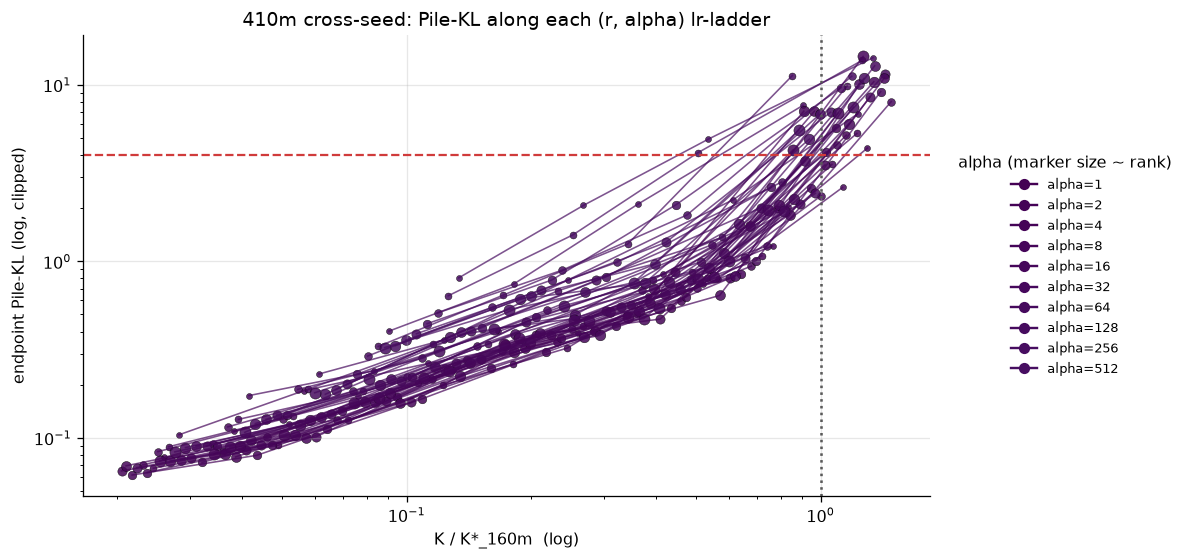

Pile-KL spread within K/K* bins (cross-seed, finite KL only); a tight p90/p10 means K is a good coordinate:


,n,median_kl,p10,p90,p90/p10
kbin,,,,,
"(-1.8, -1.6]",8,0.068,0.063,0.074,1.179
"(-1.6, -1.4]",23,0.088,0.074,0.108,1.455
"(-1.4, -1.2]",28,0.120,0.091,0.186,2.050
"(-1.2, -1.0]",31,0.183,0.136,0.329,2.421
"(-1.0, -0.8]",33,0.274,0.207,0.439,2.122
"(-0.8, -0.6]",36,0.397,0.308,0.713,2.314
"(-0.6, -0.4]",35,0.552,0.402,1.146,2.847
"(-0.4, -0.2]",33,0.810,0.603,2.043,3.389
"(-0.2, -4.44e-16]",31,2.089,1.048,7.081,6.754


In [9]:
def ladder_plot(df: pd.DataFrame, y: str, ylabel: str, title: str, yscale="log", hline=None, ylim=None):
    fig, ax = plt.subplots(figsize=(9.5, 5.2))
    colors = aplots.palette(ALPHAS, cmap="viridis")
    for (r, a), sub in df.sort_values("lr").groupby(["rank", "alpha"]):
        ax.plot(sub.K_rel, sub[y].clip(lower=1e-4, upper=60), "-", color=colors[a], lw=1.0, alpha=0.7)
        ax.scatter(sub.K_rel, sub[y].clip(lower=1e-4, upper=60), color=colors[a], s=14 + 5 * np.log2(r), alpha=0.85,
                   edgecolor="k", lw=0.3)
    for a in ALPHAS:
        ax.plot([], [], "-o", color=colors[a], label=f"alpha={a}")
    ax.axvline(1.0, color="0.35", ls=":", lw=1.6)
    if hline is not None:
        ax.axhline(hline, color="#d03b3b", ls="--", lw=1.4)
    ax.set(xscale="log", yscale=yscale, xlabel="K / K*_160m  (log)", ylabel=ylabel, title=title)
    if ylim: ax.set_ylim(*ylim)
    aplots.right_legend(ax, title="alpha (marker size ~ rank)", fontsize=8)
    plt.show()


xs = runs[(runs.arm == "410m cross-seed") & runs.probed]
ladder_plot(xs, "kl", "endpoint Pile-KL (log, clipped)", "410m cross-seed: Pile-KL along each (r, alpha) lr-ladder",
            hline=DEAD_KL_CUT)
# Spread check: at matched K/K* bins, how much of the KL variance is between-pair (alpha/rank) vs along-K?
xb = xs.assign(kbin=pd.cut(np.log10(xs.K_rel), bins=np.arange(-1.8, 0.25, 0.2)))
g = xb[np.isfinite(xb.kl)].groupby("kbin", observed=True).kl
spread = pd.DataFrame({"n": g.size(), "median_kl": g.median(), "p10": g.quantile(0.1), "p90": g.quantile(0.9)})
spread["p90/p10"] = spread.p90 / spread.p10
print("Pile-KL spread within K/K* bins (cross-seed, finite KL only); a tight p90/p10 means K is a good coordinate:")
display(spread.round(3))

## 4. Where does SL peak?

Transfer = test $p(\text{dog})$ / receiver prior (so 1 = no transfer, and every arm is on the
same scale despite different priors: 410m 0.023, 410m-seed1 0.010, 160m 0.0096). Three views:

- **4a** binned dose curves per arm (median + IQR per $K/K^\ast_{160m}$ bin; row unit one run,
  bins 0.2 dex) — the hump and its location on each width/receiver.
- **4b** the **top cells** per arm, and the peak's $K/K^\ast$ located two ways: the argmax cell,
  and the centre of mass of the top decile of transfer (robust to a single lucky cell).
- **4c** the peak per $(r,\alpha)$ pair: along each lr-ladder, which rung is best, and at what
  $K/K^\ast$ — does the hump live at one dose regardless of how the dose is composed?

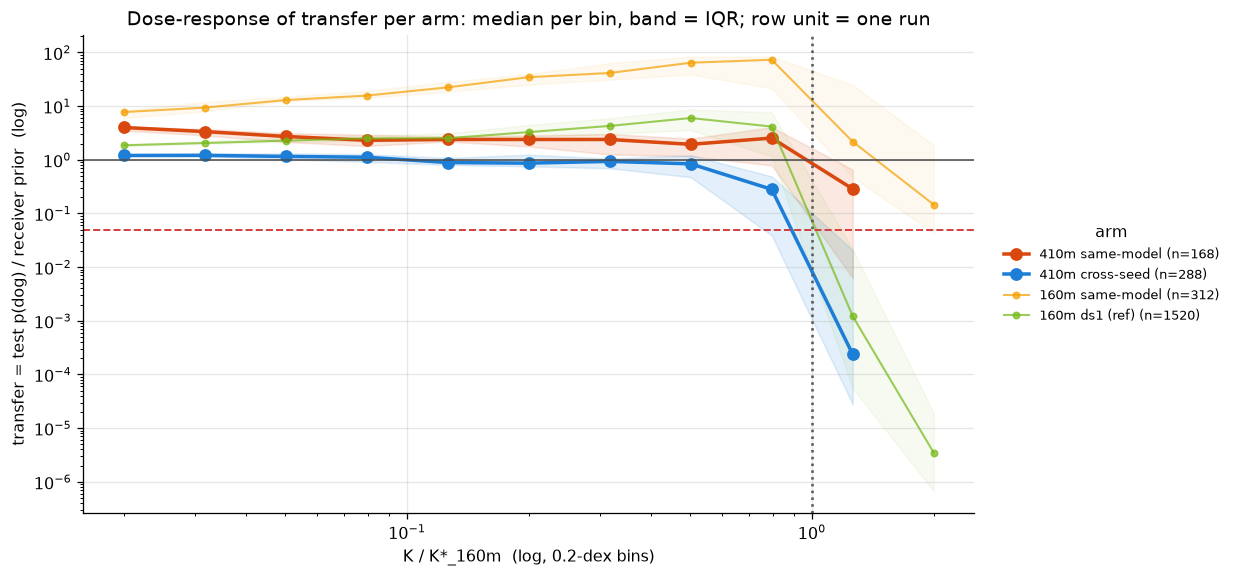

Transfer by K/K* bin (bin centre as the row index): n runs, median, max


arm      410m same-model              410m cross-seed              160m same-model                160m ds1 (ref)              
                       n median   max               n median   max               n median     max              n median    max
kmid                                                                                                                          
0.019953             5.0   4.00  5.14             8.0   1.20  1.31             8.0   7.75    9.29           34.0   1.86   2.22
0.031623            14.0   3.35  5.53            23.0   1.21  1.53             9.0   9.36   14.75           51.0   2.05   2.70
0.050119            17.0   2.72  4.94            28.0   1.16  2.04            12.0  12.97   22.16           59.0   2.27   3.68
0.079433            29.0   2.31  5.02            31.0   1.12  1.85            12.0  15.70   31.51           78.0   2.51   5.48
0.125893            20.0   2.39  4.27            33.0   0.89  2.64            14.0  22.34   35.35           92.0   2.52   7.15
0.199526            23.0   2.39  4.85            36.0   0.87  1.94            12.0  34.58   54.99           93.0   3.28  10.37
0.316228            22.0   2.39  3.95            35.0   0.93  1.71            22.0  41.46   85.53          112.0   4.28  13.36
0.501187            20.0   1.94  5.28            33.0   0.84  2.36            31.0  64.36   98.75          147.0   6.00  22.53
0.794328            12.0   2.54  9.87            31.0   0.28  2.59            30.0  73.05  102.33          211.0   4.16  34.27
1.258925             6.0   0.29  1.87            30.0   0.00  0.86            32.0   2.17   88.21          229.0   0.00  18.76
1.995262             NaN    NaN   NaN             NaN    NaN   NaN            50.0   0.15   71.88          120.0   0.00   0.01

In [10]:
EDGES = np.arange(-1.8, 0.41, 0.2)
runs["kbin"] = pd.cut(np.log10(runs.K_rel), bins=EDGES)
runs["kmid"] = runs.kbin.map(lambda b: 10 ** b.mid if pd.notna(b) else np.nan).astype(float)

fig, ax = plt.subplots(figsize=(10, 5.4))
for arm in ARMS:
    sub = runs[(runs.arm == arm)]
    g = sub.groupby("kmid", observed=True).transfer
    med, lo, hi, n = g.median(), g.quantile(0.25), g.quantile(0.75), g.size()
    big = sub.width.iloc[0] == "410m"
    ax.plot(med.index, med.values, "-o", color=ARM_COLORS[arm], lw=2.2 if big else 1.3, ms=7 if big else 4,
            alpha=1 if big else 0.7, label=f"{arm} (n={len(sub)})")
    ax.fill_between(med.index, lo.values, hi.values, color=ARM_COLORS[arm], alpha=0.12 if big else 0.06)
ax.axhline(1.0, color="0.3", lw=1.0); ax.axhline(np.exp(-3), color="#d03b3b", ls="--", lw=1.2)
ax.axvline(1.0, color="0.35", ls=":", lw=1.6)
ax.set(xscale="log", yscale="log", xlabel="K / K*_160m  (log, 0.2-dex bins)",
       ylabel="transfer = test p(dog) / receiver prior  (log)",
       title="Dose-response of transfer per arm: median per bin, band = IQR; row unit = one run")
aplots.right_legend(ax, title="arm", fontsize=8)
plt.show()

tab = (runs.groupby(["arm", "kmid"], observed=True).transfer.agg(n="size", median="median", max="max")
       .unstack("arm").swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False))
tab = tab[[c for a in ARMS for c in tab.columns if c[0] == a]]
print("Transfer by K/K* bin (bin centre as the row index): n runs, median, max")
display(tab.round(2))

In [11]:
def peak_summary(sub: pd.DataFrame) -> dict:
    s = sub.dropna(subset=["transfer"]).sort_values("transfer", ascending=False)
    top = s.head(max(3, len(s) // 10))
    return {"n": len(s), "argmax_cell": s.iloc[0].student_tag, "argmax_transfer": s.iloc[0].transfer,
            "argmax_K_rel": s.iloc[0].K_rel, "top_decile_n": len(top),
            "top_decile_median_transfer": top.transfer.median(),
            "top_decile_K_rel_geomean": float(np.exp(np.log(top.K_rel).mean())),
            "top_decile_K_rel_range": (round(top.K_rel.min(), 3), round(top.K_rel.max(), 3)),
            "frac_above_prior": float((s.transfer > 1).mean()),
            "frac_above_2x": float((s.transfer > 2).mean())}


peaks = pd.DataFrame({a: peak_summary(runs[runs.arm == a]) for a in ARMS}).T
display(peaks)
print("\nTop-6 cells per arm (row unit: one run; transfer = test p / prior):")
for a in ARMS:
    s = runs[runs.arm == a].sort_values("transfer", ascending=False).head(6)
    print(f"\n-- {a} (prior {s.test_prior.iloc[0]:.4f})")
    print(s[["student_tag", "seed", "K_rel", "test", "transfer", "kl"]].to_string(index=False, float_format=lambda v: f"{v:.3g}"))

,n,argmax_cell,argmax_transfer,argmax_K_rel,top_decile_n,top_decile_median_transfer,top_decile_K_rel_geomean,top_decile_K_rel_range,frac_above_prior,frac_above_2x
410m same-model,168,ep20_lr2e-4_r4a8,9.869413,0.679531,16,4.890918,0.115046,"(0.021, 0.739)",0.880952,0.64881
410m cross-seed,288,ep20_lr5e-6_r1a256,2.641283,0.133571,28,1.59487,0.171782,"(0.036, 0.765)",0.454861,0.013889
160m same-model,312,ep20_lr1e-4_r1a32,102.32981,0.831974,31,85.532554,0.653424,"(0.252, 1.296)",0.608974,0.583333
160m ds1 (ref),1520,ep20_lr4e-4_r32a4,34.272288,0.771967,152,9.036864,0.573856,"(0.12, 1.024)",0.565789,0.468421



Top-6 cells per arm (row unit: one run; transfer = test p / prior):

-- 410m same-model (prior 0.0229)
        student_tag  seed  K_rel  test  transfer    kl
   ep20_lr2e-4_r4a8     1   0.68 0.226      9.87  1.19
ep20_lr5e-5_r64a128     1  0.636  0.13      5.66  1.34
  ep20_lr5e-6_r1a16     1 0.0282 0.127      5.53  0.13
  ep20_lr2e-4_r32a8     1  0.569 0.121      5.28 0.876
  ep20_lr5e-6_r4a16     1 0.0251 0.118      5.14  0.11
 ep20_lr5e-6_r4a128     1 0.0805 0.115      5.02 0.435

-- 410m cross-seed (prior 0.0103)
       student_tag  seed  K_rel   test  transfer    kl
ep20_lr5e-6_r1a256     1  0.134 0.0273      2.64 0.806
  ep20_lr2e-4_r4a8     1   0.68 0.0267      2.59 0.939
 ep20_lr1e-4_r1a16     1  0.564 0.0244      2.36 0.794
 ep20_lr5e-6_r1a64     1 0.0614 0.0211      2.04  0.23
 ep20_lr2e-5_r1a32     1  0.166 0.0201      1.94   0.4
 ep20_lr1e-5_r2a32     1 0.0784 0.0191      1.85 0.183

-- 160m same-model (prior 0.0096)
      student_tag  seed  K_rel  test  transfer  kl
ep20_

410m same-model: 35 pairs; best-rung K/K* geomean 0.110, IQR 0.038-0.328; interior peaks 9/35; median peak transfer 3.84x prior


410m cross-seed: 56 pairs; best-rung K/K* geomean 0.099, IQR 0.037-0.231; interior peaks 25/56; median peak transfer 1.31x prior


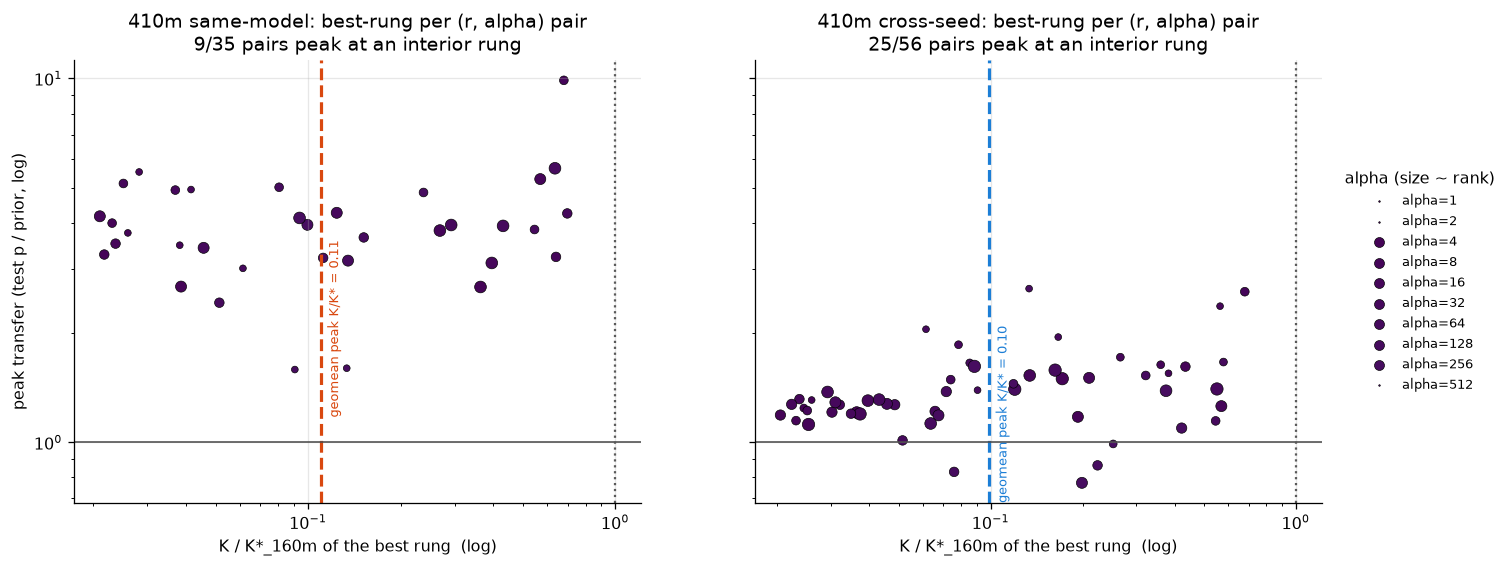

In [12]:
# 4c: per (r, alpha) pair, the best lr rung and its K/K* -- 410m arms (1 seed/cell -> the run is the cell).
def pair_peaks(sub: pd.DataFrame) -> pd.DataFrame:
    out = []
    for (r, a), g in sub.groupby(["rank", "alpha"]):
        g = g.sort_values("lr")
        if len(g) < 3:
            continue
        i = g.transfer.values.argmax()
        interior = 0 < i < len(g) - 1
        out.append({"rank": r, "alpha": a, "n_rungs": len(g), "best_lr": g.lr.iloc[i], "peak_K_rel": g.K_rel.iloc[i],
                    "peak_transfer": g.transfer.iloc[i], "interior_peak": interior,
                    "K_rel_range": (round(g.K_rel.min(), 3), round(g.K_rel.max(), 3))})
    return pd.DataFrame(out)


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, arm in zip(axes, ("410m same-model", "410m cross-seed")):
    pp = pair_peaks(runs[runs.arm == arm])
    if not len(pp):
        ax.set_title(f"{arm}: no pair has >=3 rungs yet"); continue
    colors = aplots.palette(ALPHAS, cmap="viridis")
    for a in ALPHAS:
        s = pp[pp.alpha == a]
        ax.scatter(s.peak_K_rel, s.peak_transfer, color=colors[a], s=18 + 6 * np.log2(s["rank"]), edgecolor="k", lw=0.4,
                   label=f"alpha={a}")
    gm = float(np.exp(np.log(pp.peak_K_rel).mean()))
    ax.axvline(gm, color=ARM_COLORS[arm], lw=2, ls="--")
    ax.text(gm * 1.05, ax.get_ylim()[0] if ax.get_ylim()[0] > 0 else 0.5, f"geomean peak K/K* = {gm:.2f}", color=ARM_COLORS[arm], fontsize=8, rotation=90, va="bottom")
    ax.axhline(1.0, color="0.3", lw=1); ax.axvline(1.0, color="0.35", ls=":", lw=1.4)
    ax.set(xscale="log", yscale="log", xlabel="K / K*_160m of the best rung  (log)",
           title=f"{arm}: best-rung per (r, alpha) pair\n{int(pp.interior_peak.sum())}/{len(pp)} pairs peak at an interior rung")
    print(f"{arm}: {len(pp)} pairs; best-rung K/K* geomean {gm:.3f}, IQR "
          f"{pp.peak_K_rel.quantile(.25):.3f}-{pp.peak_K_rel.quantile(.75):.3f}; "
          f"interior peaks {int(pp.interior_peak.sum())}/{len(pp)}; "
          f"median peak transfer {pp.peak_transfer.median():.2f}x prior")
axes[0].set_ylabel("peak transfer (test p / prior, log)")
aplots.right_legend(axes[1], title="alpha (size ~ rank)", fontsize=8)
plt.show()

### 4d. Trait vs integrity at the peak — is the 410m hump a *subliminal* hump?

On 160m the transfer hump sits where integrity is still essentially intact (Pile-KL ≪ cut) —
the trait arrives before the model is damaged. Plot transfer against endpoint Pile-KL for the
410m arms (row unit: one run, colour = $K/K^\ast$). If the best 410m cells are also low-KL the
hump is genuine subliminal transfer; if the best cells sit at KL of several nats the "transfer"
is riding on generic degradation of the output distribution.

410m same-model: top-10 transfer cells have Pile-KL median 0.34 nats (range 0.11-1.44); Spearman(transfer, KL) over alive runs = -0.33
410m cross-seed: top-10 transfer cells have Pile-KL median 0.47 nats (range 0.18-1.37); Spearman(transfer, KL) over alive runs = -0.45


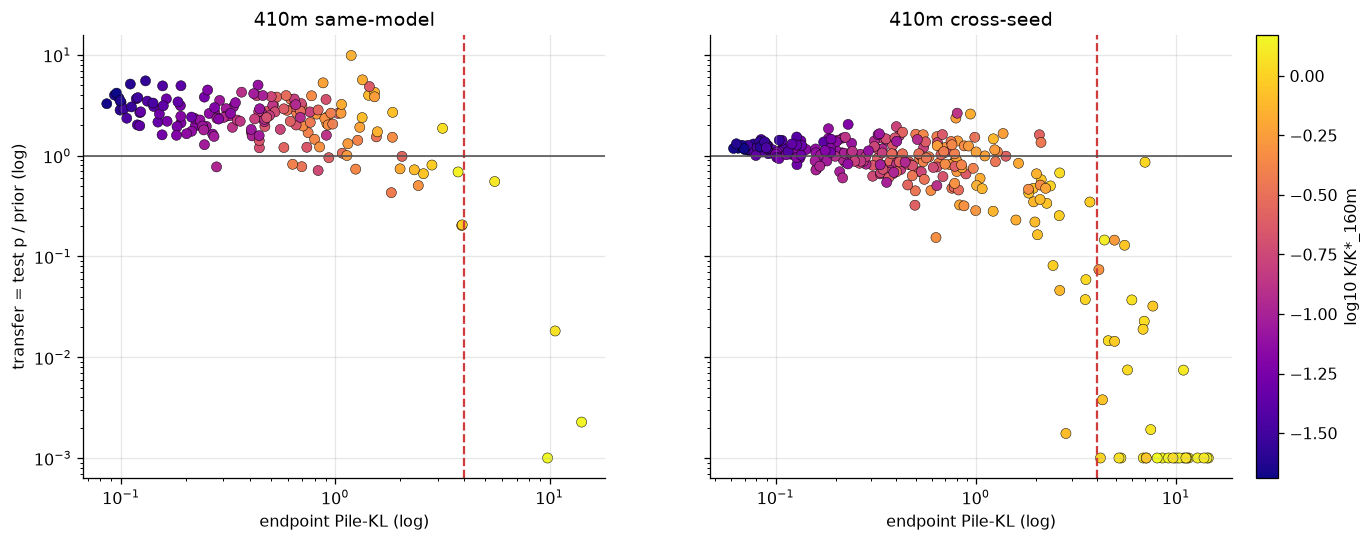

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5), sharey=True)
for ax, arm in zip(axes, ("410m same-model", "410m cross-seed")):
    sub = runs[(runs.arm == arm) & runs.probed & np.isfinite(runs.kl)]
    sc = ax.scatter(sub.kl, sub.transfer.clip(lower=1e-3), c=np.log10(sub.K_rel), cmap="plasma", s=40, edgecolor="k", lw=0.3)
    ax.axvline(DEAD_KL_CUT, color="#d03b3b", ls="--", lw=1.4); ax.axhline(1.0, color="0.3", lw=1)
    ax.set(xscale="log", yscale="log", xlabel="endpoint Pile-KL (log)", title=f"{arm}")
    top = sub.sort_values("transfer", ascending=False).head(10)
    print(f"{arm}: top-10 transfer cells have Pile-KL median {top.kl.median():.2f} nats "
          f"(range {top.kl.min():.2f}-{top.kl.max():.2f}); Spearman(transfer, KL) over alive runs = "
          f"{sub[~sub.dead_kl][['transfer','kl']].corr('spearman').iloc[0,1]:+.2f}")
axes[0].set_ylabel("transfer = test p / prior (log)")
cb = fig.colorbar(sc, ax=axes, fraction=0.025, pad=0.02); cb.set_label("log10 K/K*_160m")
plt.show()

### 4e. Same-model transfer map — house $K/K^\ast$ × $\alpha$ × rank grid (ep20 endpoint)

The standard campaign figure (`aplots.facet_grid_heatmaps`, as in
`collapse_campaigns_k_alpha_rank.ipynb`): row = $K/K^\ast_{160m}$ bin (0.05 wide, the house
ladder extended down to 0 so the 410m low-dose rungs are not dropped), col = $\alpha$, panel =
rank; value = **mean endpoint test $p(\text{dog})$** over the runs in that square (house colour
scale `P_VMAX` = 0.2), n = runs. Dashed rule = $K/K^\ast_{160m}=1$; solid rule = this arm's
own integrity $K^\ast$. Blank = no landed run in that square. The receiver prior is 0.023, so
0.1 ≈ 4× prior.

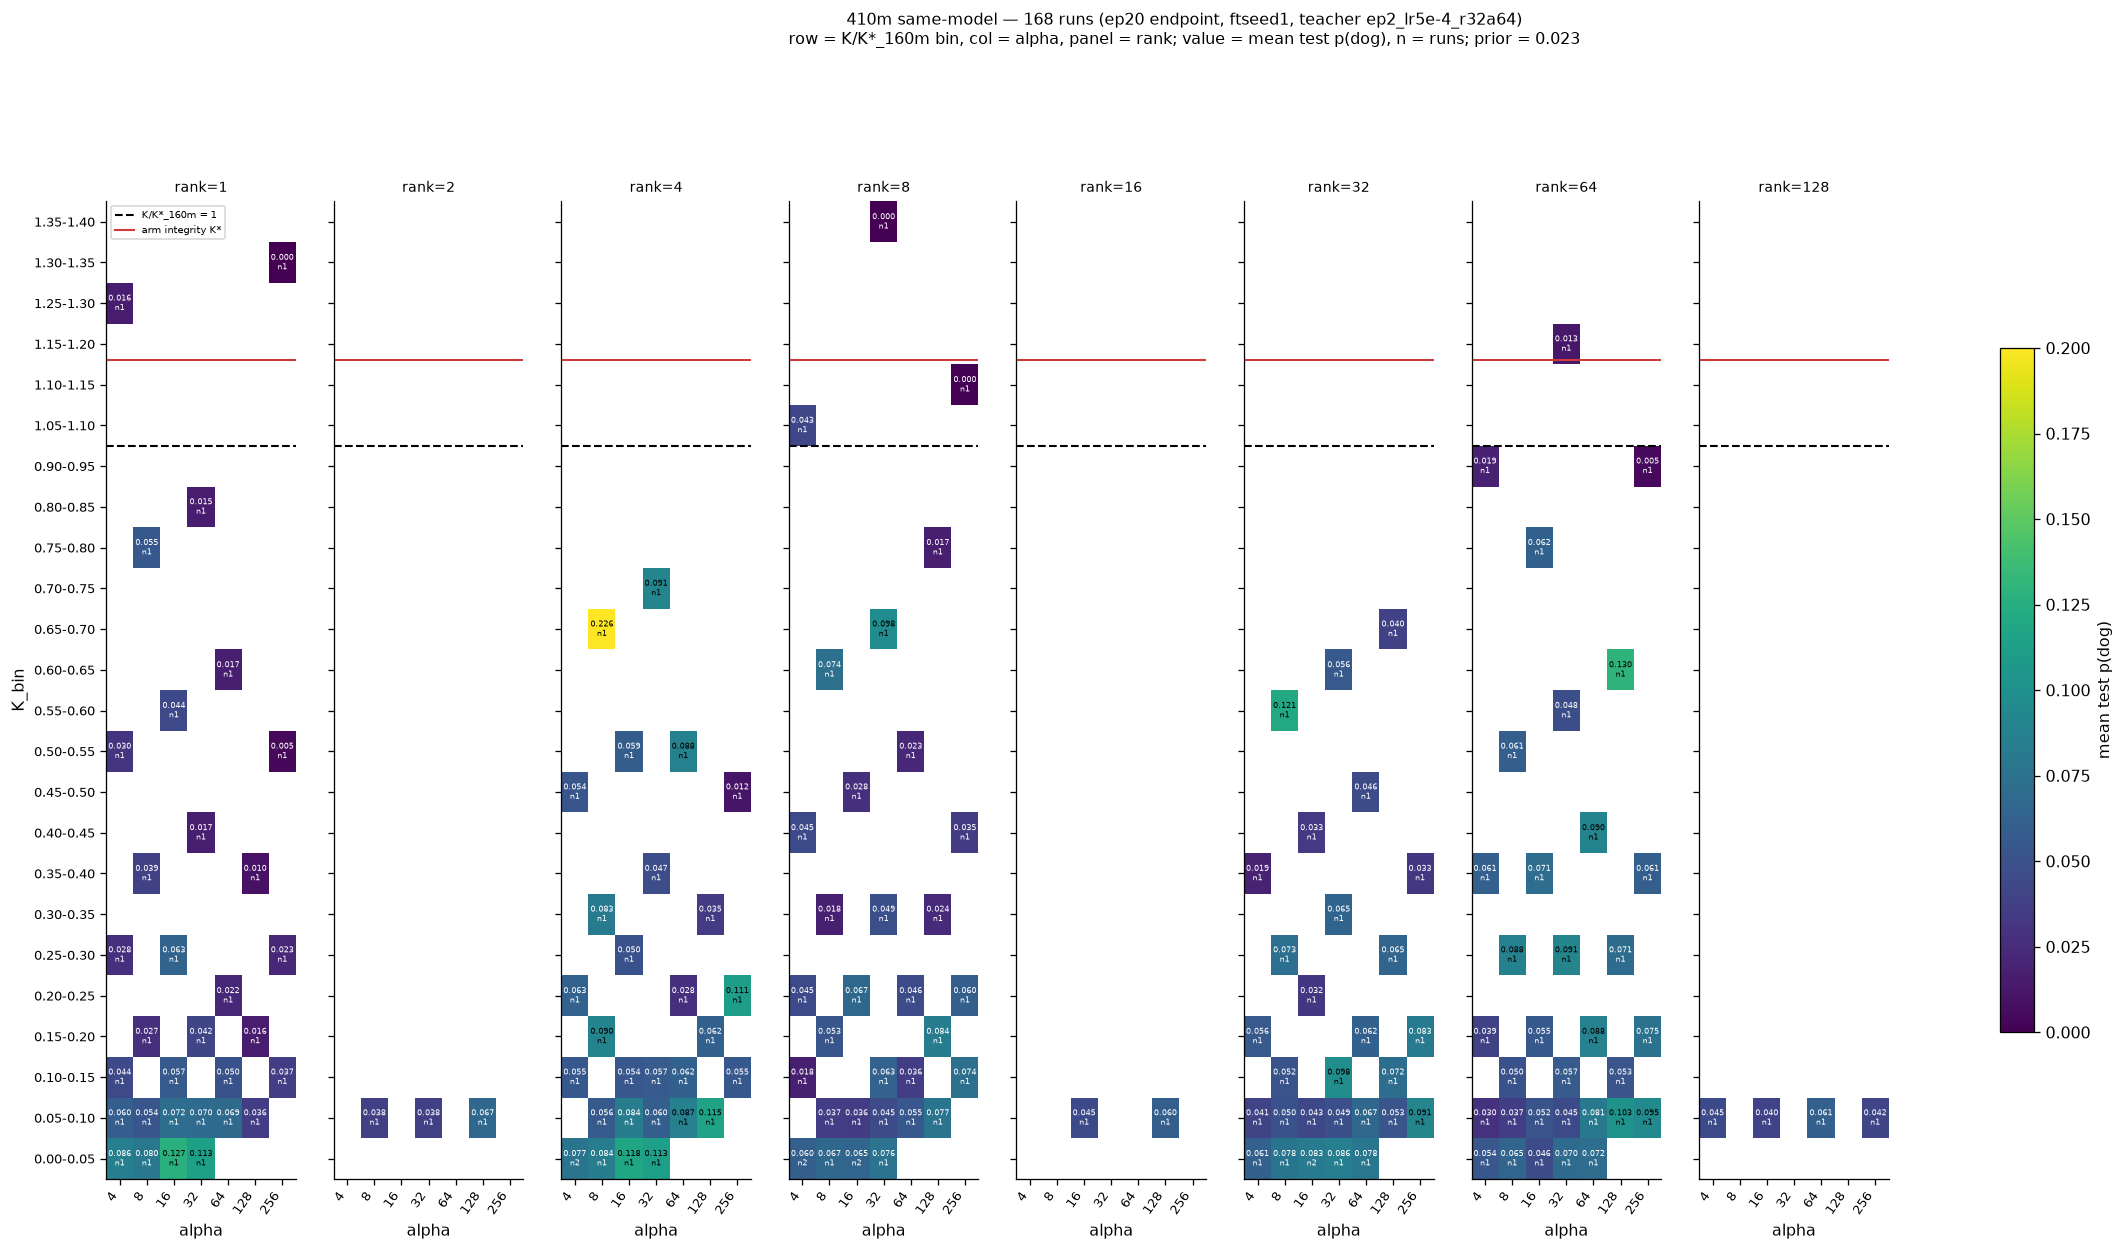

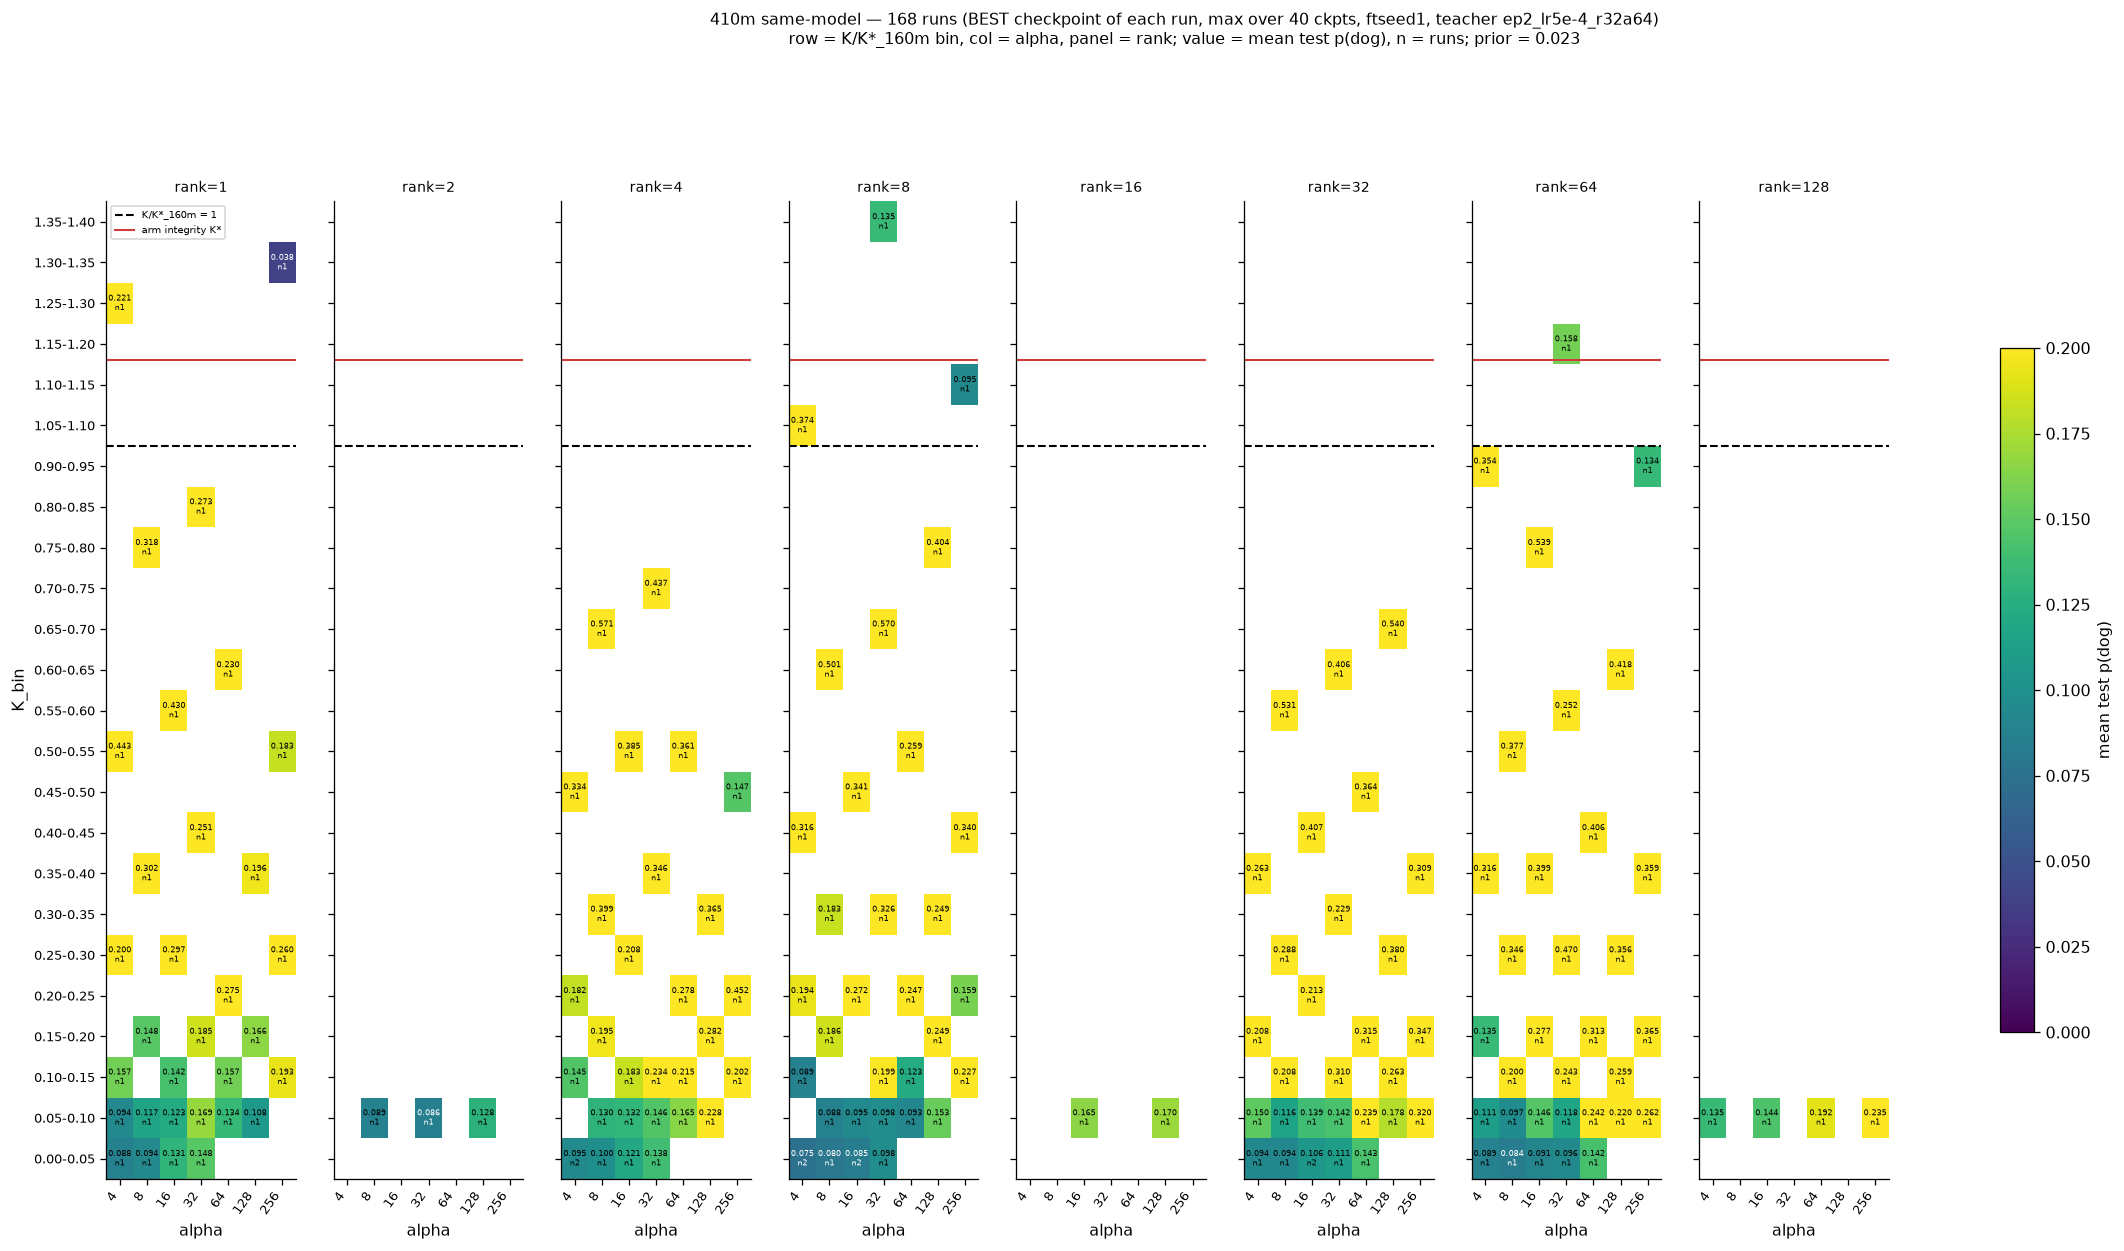

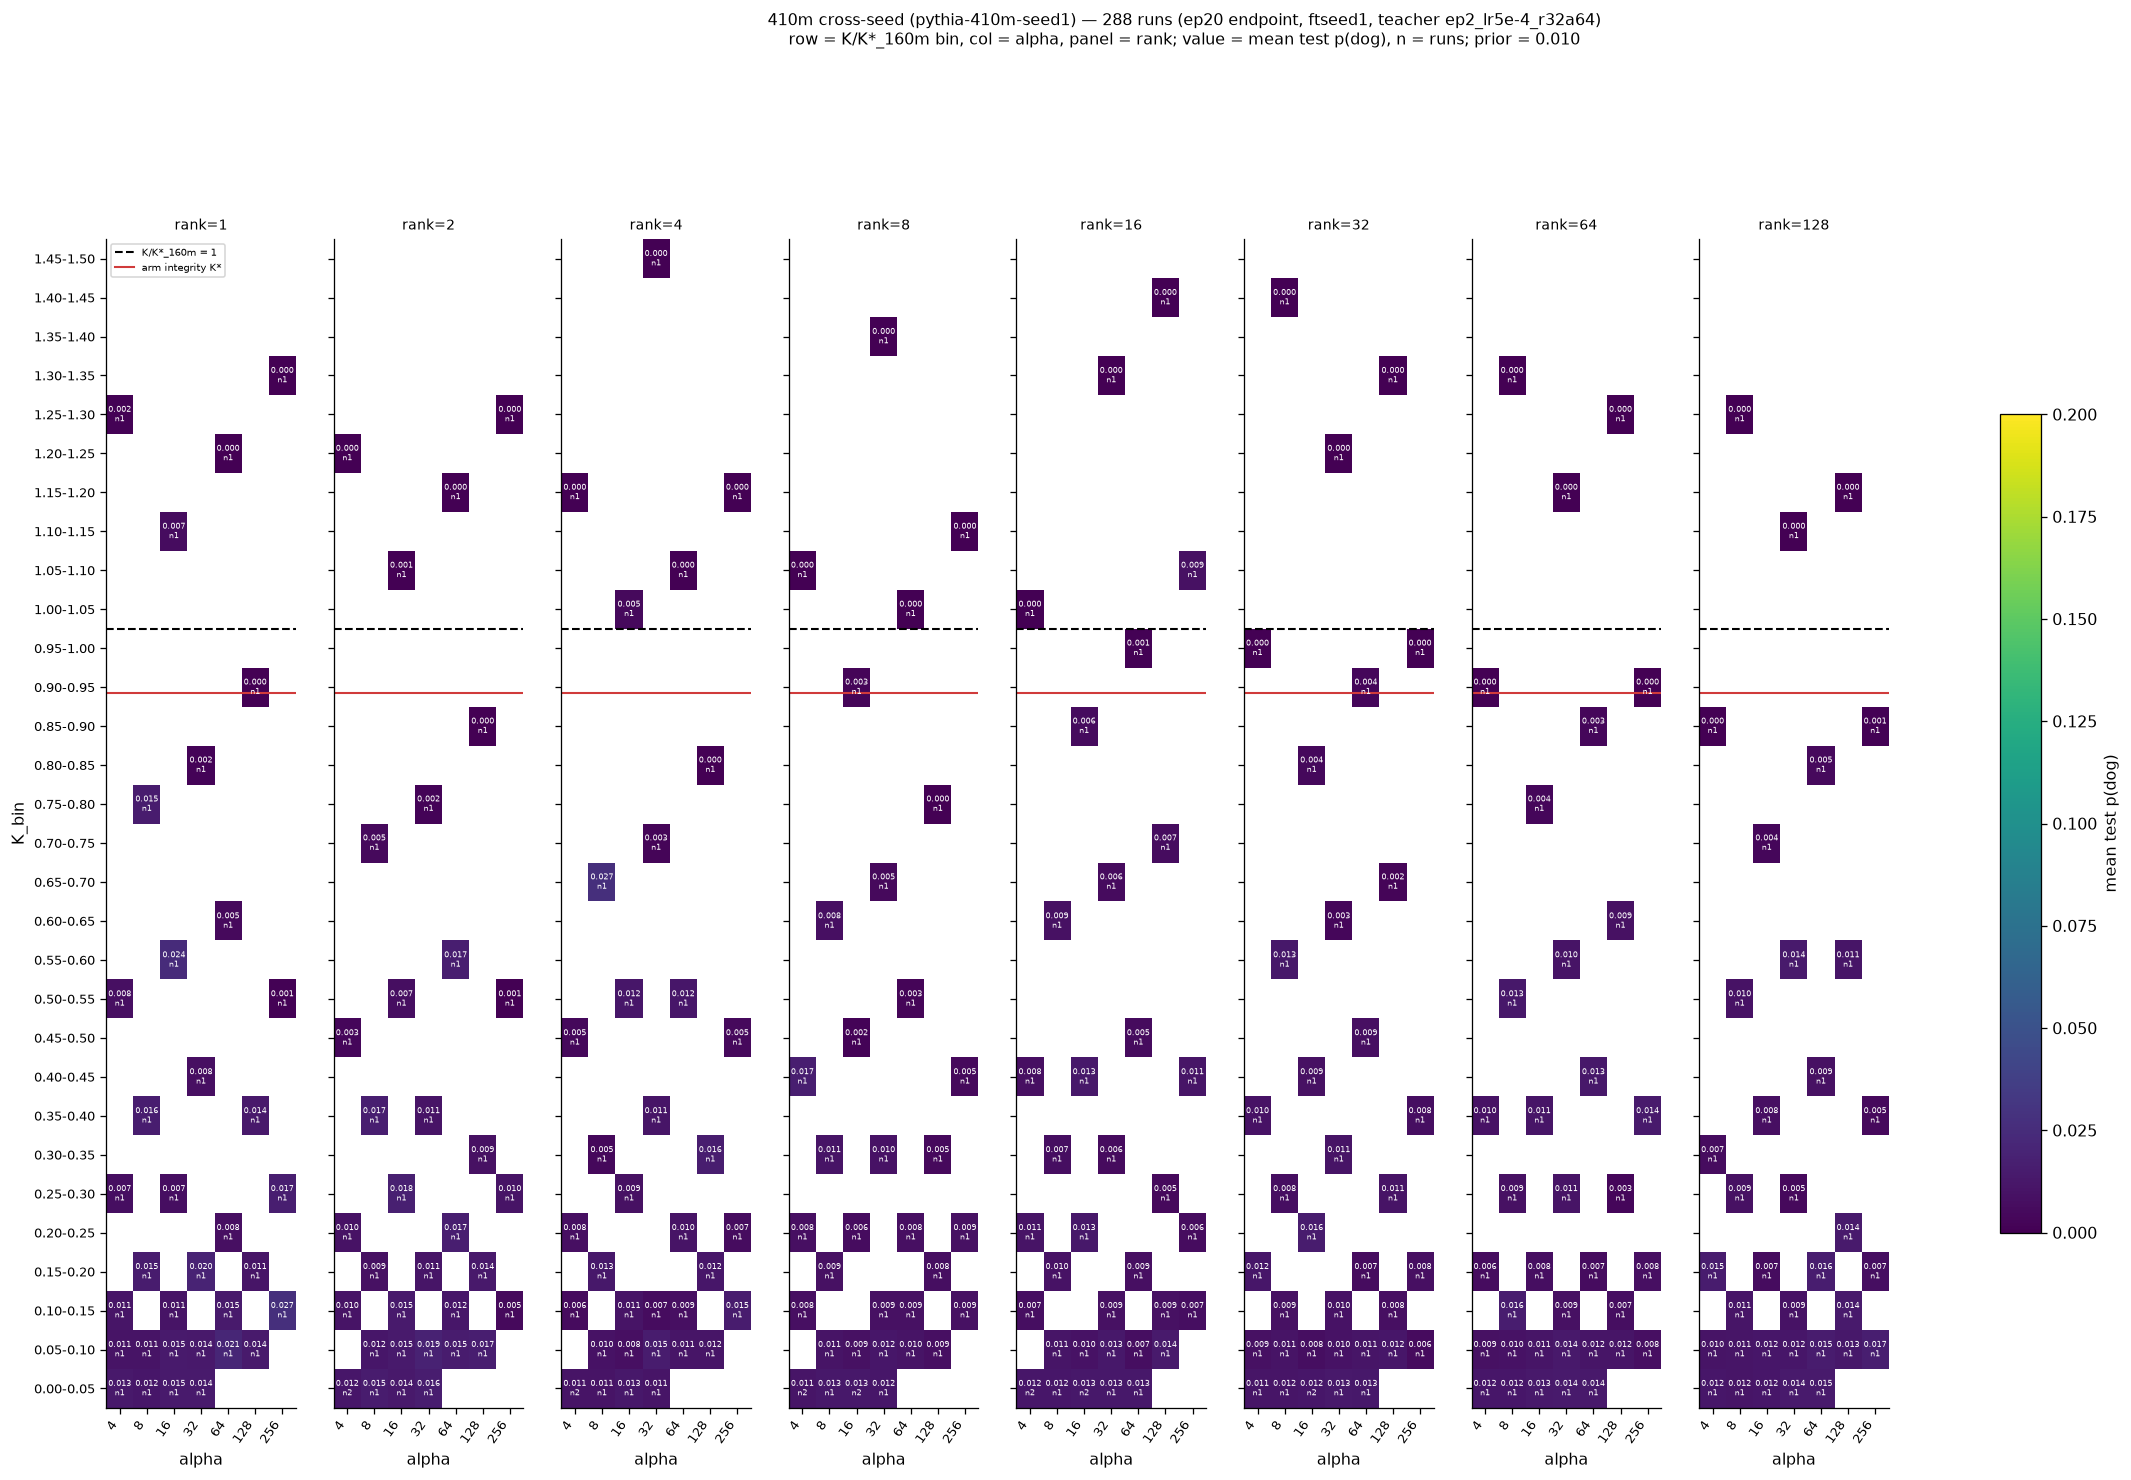

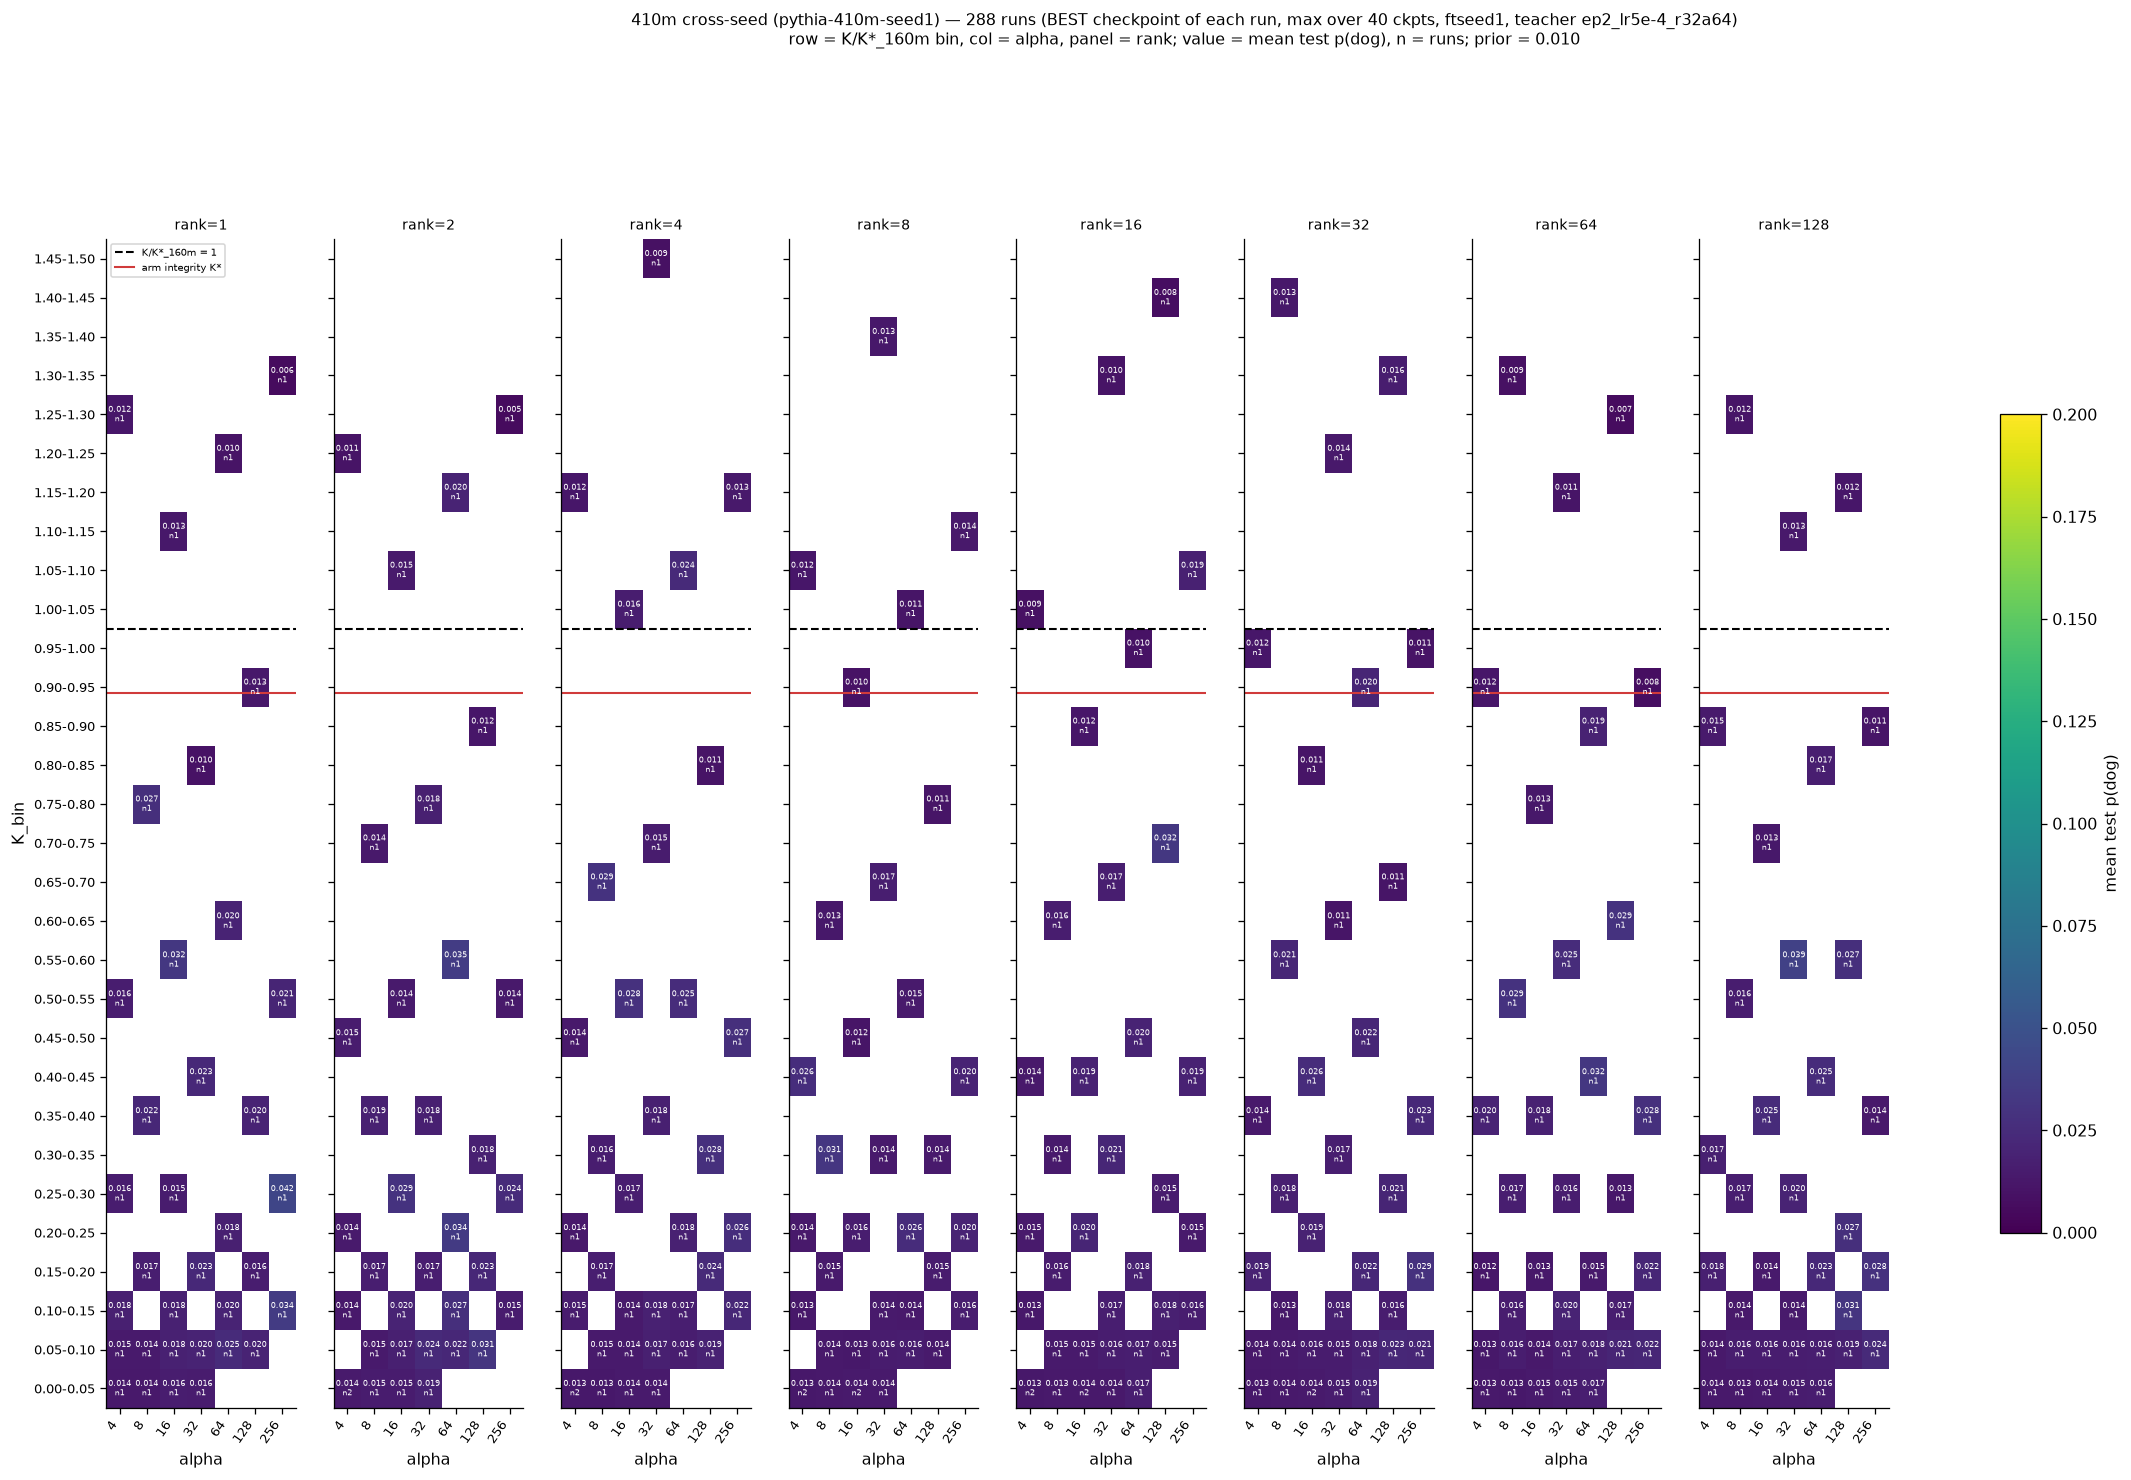

In [14]:
BIN_W = 0.05
EDGES_H = np.round(np.arange(0.0, 1.50 + 1e-9, BIN_W), 2)
BIN_LABELS = [f"{lo:.2f}-{lo + BIN_W:.2f}" for lo in EDGES_H[:-1]]
P_VMAX = 0.2                                  # house colour scale for mean test p


def k_bin(k_rel):
    return pd.cut(pd.Series(np.asarray(k_rel, float)), bins=EDGES_H, labels=BIN_LABELS,
                  right=False, include_lowest=True).astype(str).values


def best_ckpt_p(leaf: str) -> float:
    f = Path(leaf) / "eval" / "pref_traj.json"
    return max(p["test"]["p_target"] for p in read_json(f)["points"]) if f.exists() else np.nan


def house_grid(sub: pd.DataFrame, arm: str, kstar_arm: float | None, val: str = "test", what: str = "ep20 endpoint"):
    sub = sub.assign(K_bin=k_bin(sub.K_rel)).dropna(subset=[val])
    k_order = [b for b in BIN_LABELS if b in set(sub.K_bin)]
    orders = {"K_bin": k_order, "alpha": sorted(sub.alpha.unique()), "rank": sorted(sub["rank"].unique())}
    boundary_row = next((i for i, b in enumerate(k_order) if float(b.split("-")[0]) >= 1.0), len(k_order))
    fig = aplots.facet_grid_heatmaps(
        sub, row="K_bin", col="alpha", val=val, col_facet="rank", agg="mean",
        orders=orders, show_n=True, vmin=0.0, vmax=P_VMAX, cmap="viridis", fmt="{:.3f}",
        panel_w=3.0, row_h=0.36, cell_fontsize=4.8,
        title=(f"{arm} — {len(sub)} runs ({what}, ftseed1, teacher {TEACHER})\n"
               "row = K/K*_160m bin, col = alpha, panel = rank; value = mean test p(dog), n = runs; "
               f"prior = {sub.test_prior.iloc[0]:.3f}"),
        cbar_label="mean test p(dog)")

    def _row_pos(v):
        for i, bl in enumerate(k_order):
            lo = float(bl.split("-")[0])
            if lo <= v < lo + BIN_W:
                return i + (v - lo) / BIN_W - 0.5
        return None

    for i, ax in enumerate(a for a in fig.axes if a.get_label() != "<colorbar>"):
        if i % len(orders["rank"]):
            ax.set_yticklabels([])
        ax.axhline(boundary_row - 0.5, color="k", ls="--", lw=1.3, label="K/K*_160m = 1" if i == 0 else None)
        if kstar_arm is not None and (pos := _row_pos(kstar_arm / KSTAR_160)) is not None:
            ax.axhline(pos, color="#d03b3b", ls="-", lw=1.3, label="arm integrity K*" if i == 0 else None)
    fig.axes[0].legend(loc="upper left", fontsize=6, frameon=True)
    plt.show()


same = runs[runs.arm == "410m same-model"].copy()
same["best_test"] = [best_ckpt_p(l) for l in same.leaf]
house_grid(same, "410m same-model", KSTAR_410.get("410m same-model"))
house_grid(same, "410m same-model", KSTAR_410.get("410m same-model"), val="best_test",
           what="BEST checkpoint of each run, max over 40 ckpts")

# The cross-seed receiver (pythia-410m-seed1, no shared factor with the teacher) on the same two views
# and the same colour scale. Its prior is 0.010, so 0.02 ~ 2x prior.
xseed = runs[runs.arm == "410m cross-seed"].copy()
xseed["best_test"] = [best_ckpt_p(l) for l in xseed.leaf]
house_grid(xseed, "410m cross-seed (pythia-410m-seed1)", KSTAR_410.get("410m cross-seed"))
house_grid(xseed, "410m cross-seed (pythia-410m-seed1)", KSTAR_410.get("410m cross-seed"), val="best_test",
           what="BEST checkpoint of each run, max over 40 ckpts")

## 5. When along training does the trait peak?

Each 410m run carries `eval/pref_traj.json` (test $p(\text{dog})$ at 40 checkpoints, every 625
of 25k steps) and `eval/pile_kl_traj.json`. For every run take the checkpoint of maximal test
$p$; report (i) the step fraction at which the trait peaks, (ii) the **overshoot** = peak / endpoint
transfer (>1 means the trait rose then decayed within the run), as a function of dose. On 160m
the natural trajectories were monotone (no overshoot). Row unit: one run.

trajectories read for 456/456 410m runs


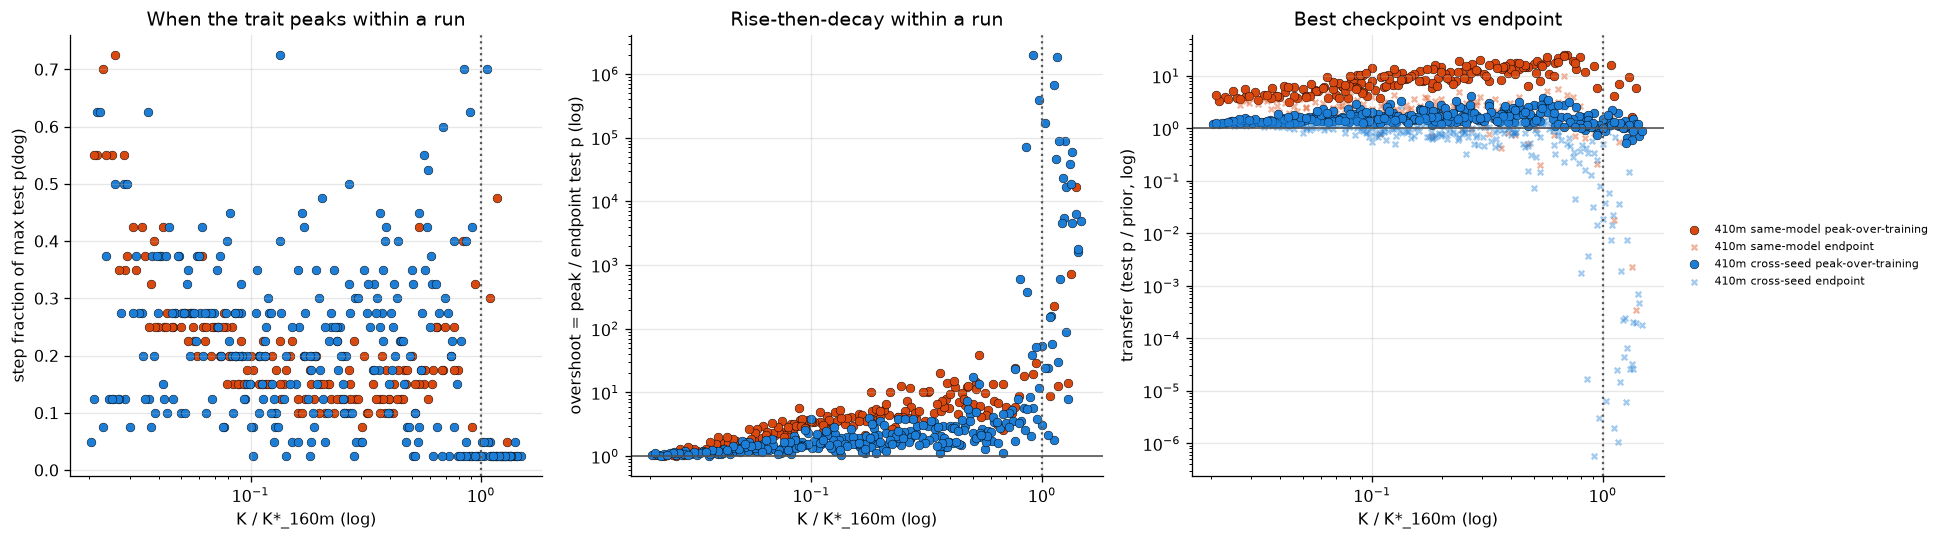

By dose band (row unit: one run): where in training the trait peaks, how much it decays by the end, and the Pile-KL at the peak checkpoint


n  peak_step_frac_med  overshoot_med  frac_overshoot_gt2  peak_transfer_med  end_transfer_med  kl_at_peak_med
arm             kband                                                                                                                      
410m cross-seed (0.0, 0.05]  43               0.275          1.118               0.000              1.359             1.209           0.063
                (0.05, 0.1]  47               0.275          1.426               0.085              1.541             1.103           0.093
                (0.1, 0.2]   53               0.175          1.690               0.283              1.609             0.883           0.153
                (0.2, 0.4]   51               0.250          1.992               0.490              1.732             0.874           0.279
                (0.4, 0.8]   47               0.225          2.786               0.745              1.915             0.811           0.562
                (0.8, 1.2]   32               0.025         45.136               0.969              1.171             0.027           0.311
                (1.2, 10.0]  15               0.025       5454.854               1.000              1.001             0.000           0.303
410m same-model (0.0, 0.05]  26               0.362          1.286               0.000              4.127             3.354           0.092
                (0.05, 0.1]  39               0.225          2.627               0.769              6.055             2.347           0.135
                (0.1, 0.2]   33               0.150          3.679               1.000              8.826             2.399           0.185
                (0.2, 0.4]   32               0.125          5.713               1.000             12.339             2.167           0.308
                (0.4, 0.8]   29               0.175          7.238               1.000             16.769             2.083           0.659
                (0.8, 1.2]    6               0.312         18.516               1.000              9.381             0.608           2.095
                (1.2, 10.0]   3               0.025        734.173               1.000              5.873             0.002           1.232

In [15]:
def traj_stats(leaf: str) -> dict:
    f = Path(leaf) / "eval" / "pref_traj.json"
    g = Path(leaf) / "eval" / "pile_kl_traj.json"
    if not f.exists():
        return {}
    pts = read_json(f)["points"]
    steps = np.array([p["step"] for p in pts]); tp = np.array([p["test"]["p_target"] for p in pts])
    i = int(tp.argmax())
    out = {"peak_step_frac": steps[i] / steps.max(), "peak_test": tp[i], "end_test": tp[-1],
           "overshoot": tp[i] / max(tp[-1], 1e-9), "n_ckpt": len(pts)}
    if g.exists():
        kp = read_json(g)["points"]; kl = np.array([p["kl_base_adapted"] for p in kp]); ks = np.array([p["step"] for p in kp])
        out["kl_at_peak"] = float(np.interp(steps[i], ks, kl)); out["kl_end_traj"] = float(kl[-1])
        cross = np.where(kl > DEAD_KL_CUT)[0]
        out["kl_cross_step_frac"] = float(ks[cross[0]] / ks.max()) if len(cross) else np.nan
    return out


r410 = runs[runs.width == "410m"].copy()
ts = pd.DataFrame([traj_stats(l) for l in r410.leaf], index=r410.index)
r410 = r410.join(ts)
r410["peak_transfer"] = r410.peak_test / r410.test_prior
have = r410.dropna(subset=["peak_step_frac"])
print(f"trajectories read for {len(have)}/{len(r410)} 410m runs")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for arm in ("410m same-model", "410m cross-seed"):
    s = have[have.arm == arm]
    axes[0].scatter(s.K_rel, s.peak_step_frac, color=ARM_COLORS[arm], s=30, edgecolor="k", lw=0.3, label=arm)
    axes[1].scatter(s.K_rel, s.overshoot, color=ARM_COLORS[arm], s=30, edgecolor="k", lw=0.3, label=arm)
    axes[2].scatter(s.K_rel, s.peak_transfer, color=ARM_COLORS[arm], s=30, edgecolor="k", lw=0.3, label=f"{arm} peak-over-training")
    axes[2].scatter(s.K_rel, s.transfer, color=ARM_COLORS[arm], s=12, alpha=0.4, marker="x", label=f"{arm} endpoint")
for ax in axes:
    ax.axvline(1.0, color="0.35", ls=":", lw=1.4); ax.set_xscale("log"); ax.set_xlabel("K / K*_160m (log)")
axes[0].set(ylabel="step fraction of max test p(dog)", title="When the trait peaks within a run")
axes[1].set(yscale="log", ylabel="overshoot = peak / endpoint test p (log)", title="Rise-then-decay within a run")
axes[1].axhline(1, color="0.3", lw=1)
axes[2].set(yscale="log", ylabel="transfer (test p / prior, log)", title="Best checkpoint vs endpoint")
axes[2].axhline(1, color="0.3", lw=1)
aplots.right_legend(axes[2], fontsize=7)
plt.tight_layout(); plt.show()

summ = (have.assign(kband=pd.cut(have.K_rel, [0, 0.05, 0.1, 0.2, 0.4, 0.8, 1.2, 10]))
        .groupby(["arm", "kband"], observed=True)
        .agg(n=("leaf", "size"), peak_step_frac_med=("peak_step_frac", "median"), overshoot_med=("overshoot", "median"),
             frac_overshoot_gt2=("overshoot", lambda v: float((v > 2).mean())),
             peak_transfer_med=("peak_transfer", "median"), end_transfer_med=("transfer", "median"),
             kl_at_peak_med=("kl_at_peak", "median")))
print("By dose band (row unit: one run): where in training the trait peaks, how much it decays by the end, "
      "and the Pile-KL at the peak checkpoint")
display(summ.round(3))

### 5b. Transfer vs Pile-KL — along the trajectory

Two comparisons. **Endpoint**: transfer vs endpoint Pile-KL (§4d) is *negatively* correlated
among alive runs — the most-damaged survivors carry the least trait. **Along training**: for
each run, the per-checkpoint trait (test $p$/prior) against the per-checkpoint Pile-KL
(`pile_kl_traj.json`, interpolated onto the preference checkpoints). KL rises monotonically with
training while the trait rises then decays, so within a run the two are anti-correlated over
most of the schedule; the trait peak sits at a small fraction of the endpoint KL. Left: every
alive run's (KL, trait) path, faint, with the peak checkpoint marked. Right: best-checkpoint
and endpoint transfer by endpoint-KL bin. Row unit: one run (integrity-alive at the endpoint).

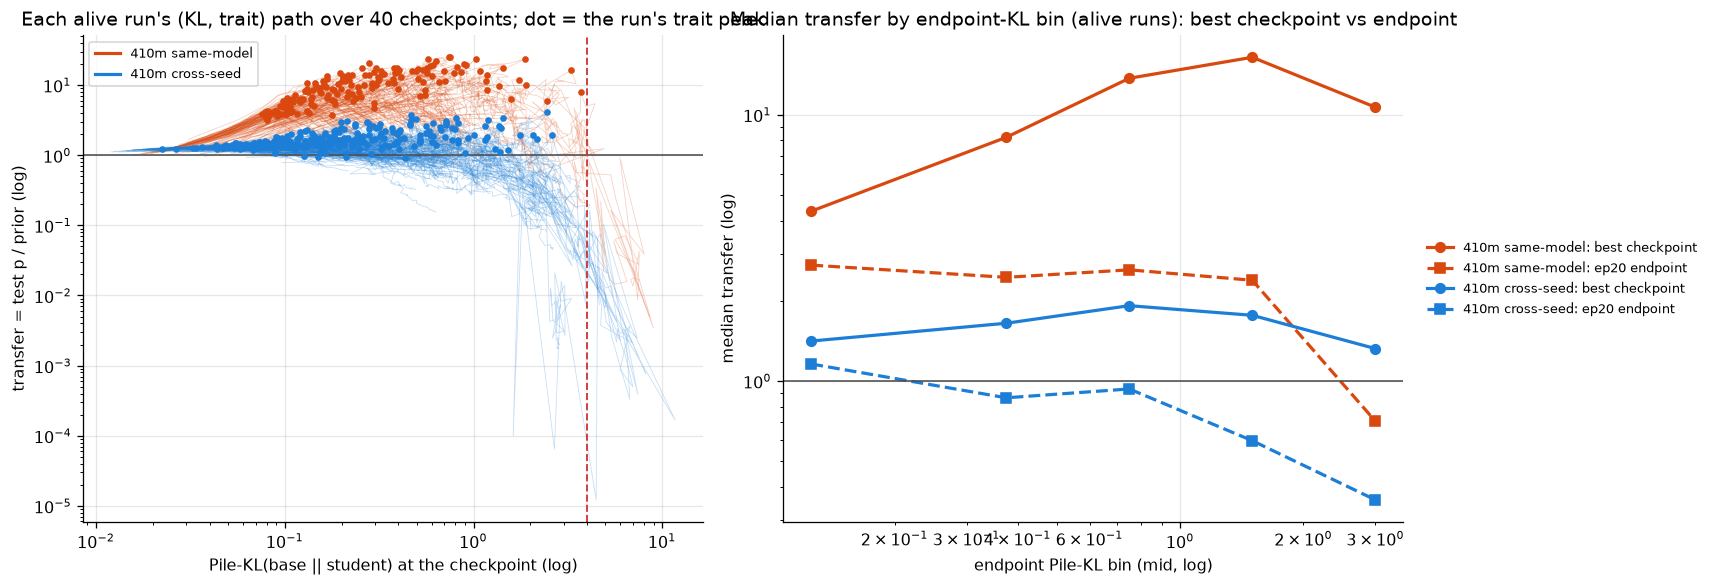

Alive runs. spearman_end = rank corr(endpoint transfer, endpoint KL); rho_within = per-run Spearman of trait vs KL across checkpoints.


,n,spearman_end,kl_at_peak_med,kl_end_med,rho_within_med,frac_rho_neg
arm,,,,,,
410m cross-seed,252,-0.450,0.162,0.368,-0.795,0.889
410m same-model,164,-0.328,0.207,0.455,-0.780,0.933



By endpoint-KL bin (median over runs): best-checkpoint vs endpoint transfer, KL at the peak, and where the peak sits in training


n  transfer_peak  transfer_end  kl_at_peak  peak_frac
arm             kl_bin                                                             
410m cross-seed (0.0, 0.25]  97           1.41          1.16        0.07       0.20
                (0.25, 0.5]  60           1.65          0.86        0.18       0.20
                (0.5, 1.0]   58           1.92          0.93        0.39       0.24
                (1.0, 2.0]   19           1.76          0.60        0.83       0.22
                (2.0, 4.0]   18           1.32          0.36        0.77       0.06
410m same-model (0.0, 0.25]  47           4.34          2.72        0.10       0.25
                (0.25, 0.5]  42           8.22          2.45        0.17       0.20
                (0.5, 1.0]   44          13.70          2.61        0.32       0.15
                (1.0, 2.0]   21          16.43          2.39        0.74       0.15
                (2.0, 4.0]   10          10.67          0.71        1.66       0.18

In [16]:
def traj_pairs(leaf: str, prior: float):
    f, g = Path(leaf) / "eval" / "pref_traj.json", Path(leaf) / "eval" / "pile_kl_traj.json"
    if not (f.exists() and g.exists()):
        return None
    P, K = read_json(f)["points"], read_json(g)["points"]
    st = np.array([p["step"] for p in P], float); tp = np.array([p["test"]["p_target"] for p in P]) / prior
    kl = np.interp(st, [p["step"] for p in K], [p["kl_base_adapted"] for p in K])
    return st, tp, kl


fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
tab = []
for arm in ("410m same-model", "410m cross-seed"):
    sub = runs[(runs.arm == arm) & runs.probed & ~runs.dead_kl]
    c = ARM_COLORS[arm]
    for r in sub.itertuples():
        out = traj_pairs(r.leaf, r.test_prior)
        if out is None: continue
        st, tp, kl = out; i = int(tp.argmax())
        axes[0].plot(kl, tp, color=c, lw=0.5, alpha=0.25)
        axes[0].scatter(kl[i], tp[i], color=c, s=10, zorder=3)
        rho = pd.Series(tp).corr(pd.Series(kl), method="spearman")
        tab.append({"arm": arm, "student_tag": r.student_tag, "kl_end": r.kl, "transfer_end": r.transfer,
                    "transfer_peak": tp[i], "kl_at_peak": kl[i], "peak_frac": st[i] / st[-1], "rho_within": rho})
    axes[0].plot([], [], color=c, lw=2, label=arm)
axes[0].axhline(1, color="0.3", lw=1); axes[0].axvline(DEAD_KL_CUT, color="#d03b3b", ls="--", lw=1.2)
axes[0].set(xscale="log", yscale="log", xlabel="Pile-KL(base || student) at the checkpoint (log)", ylabel="transfer = test p / prior (log)",
            title="Each alive run's (KL, trait) path over 40 checkpoints; dot = the run's trait peak")
axes[0].legend(fontsize=8)
T = pd.DataFrame(tab)
T["kl_bin"] = pd.cut(T.kl_end, [0, 0.25, 0.5, 1, 2, 4])
for arm in ("410m same-model", "410m cross-seed"):
    g = T[T.arm == arm].groupby("kl_bin", observed=True)
    x = [b.mid for b in g.size().index]
    axes[1].plot(x, g.transfer_peak.median(), "-o", color=ARM_COLORS[arm], lw=2, label=f"{arm}: best checkpoint")
    axes[1].plot(x, g.transfer_end.median(), "--s", color=ARM_COLORS[arm], lw=2, label=f"{arm}: ep20 endpoint")
axes[1].axhline(1, color="0.3", lw=1)
axes[1].set(xscale="log", yscale="log", xlabel="endpoint Pile-KL bin (mid, log)", ylabel="median transfer (log)",
            title="Median transfer by endpoint-KL bin (alive runs): best checkpoint vs endpoint")
aplots.right_legend(axes[1], fontsize=8)
plt.tight_layout(); plt.show()

summ = (T.groupby("arm").agg(n=("student_tag", "size"),
                             spearman_end=("transfer_end", lambda v: T.loc[v.index, ["transfer_end", "kl_end"]].corr("spearman").iloc[0, 1]),
                             kl_at_peak_med=("kl_at_peak", "median"), kl_end_med=("kl_end", "median"),
                             rho_within_med=("rho_within", "median"), frac_rho_neg=("rho_within", lambda v: float((v < 0).mean()))))
print("Alive runs. spearman_end = rank corr(endpoint transfer, endpoint KL); rho_within = per-run Spearman of trait vs KL across checkpoints.")
display(summ.round(3))
print("\nBy endpoint-KL bin (median over runs): best-checkpoint vs endpoint transfer, KL at the peak, and where the peak sits in training")
display(T.groupby(["arm", "kl_bin"], observed=True).agg(n=("student_tag", "size"), transfer_peak=("transfer_peak", "median"),
        transfer_end=("transfer_end", "median"), kl_at_peak=("kl_at_peak", "median"), peak_frac=("peak_frac", "median")).round(2))

### 5c. Checkpoint by checkpoint — transfer and Pile-KL on the same clock

Per arm, runs are stratified by dose band ($K/K^\ast_{160m}$) and, at each of the 40
checkpoints, the **median transfer** (top row) and **median Pile-KL** (bottom row) over the runs
in the band are plotted against the training-step fraction. Faint lines are individual runs.
Integrity-dead endpoints are included (they are what the high bands become), so the bottom panels
show the KL climb all the way to the cut. The triangle on each transfer curve marks the band's
median-peak checkpoint; the same x is marked on the KL curve so the KL *at that moment* can be
read directly. Row unit: one run per checkpoint.

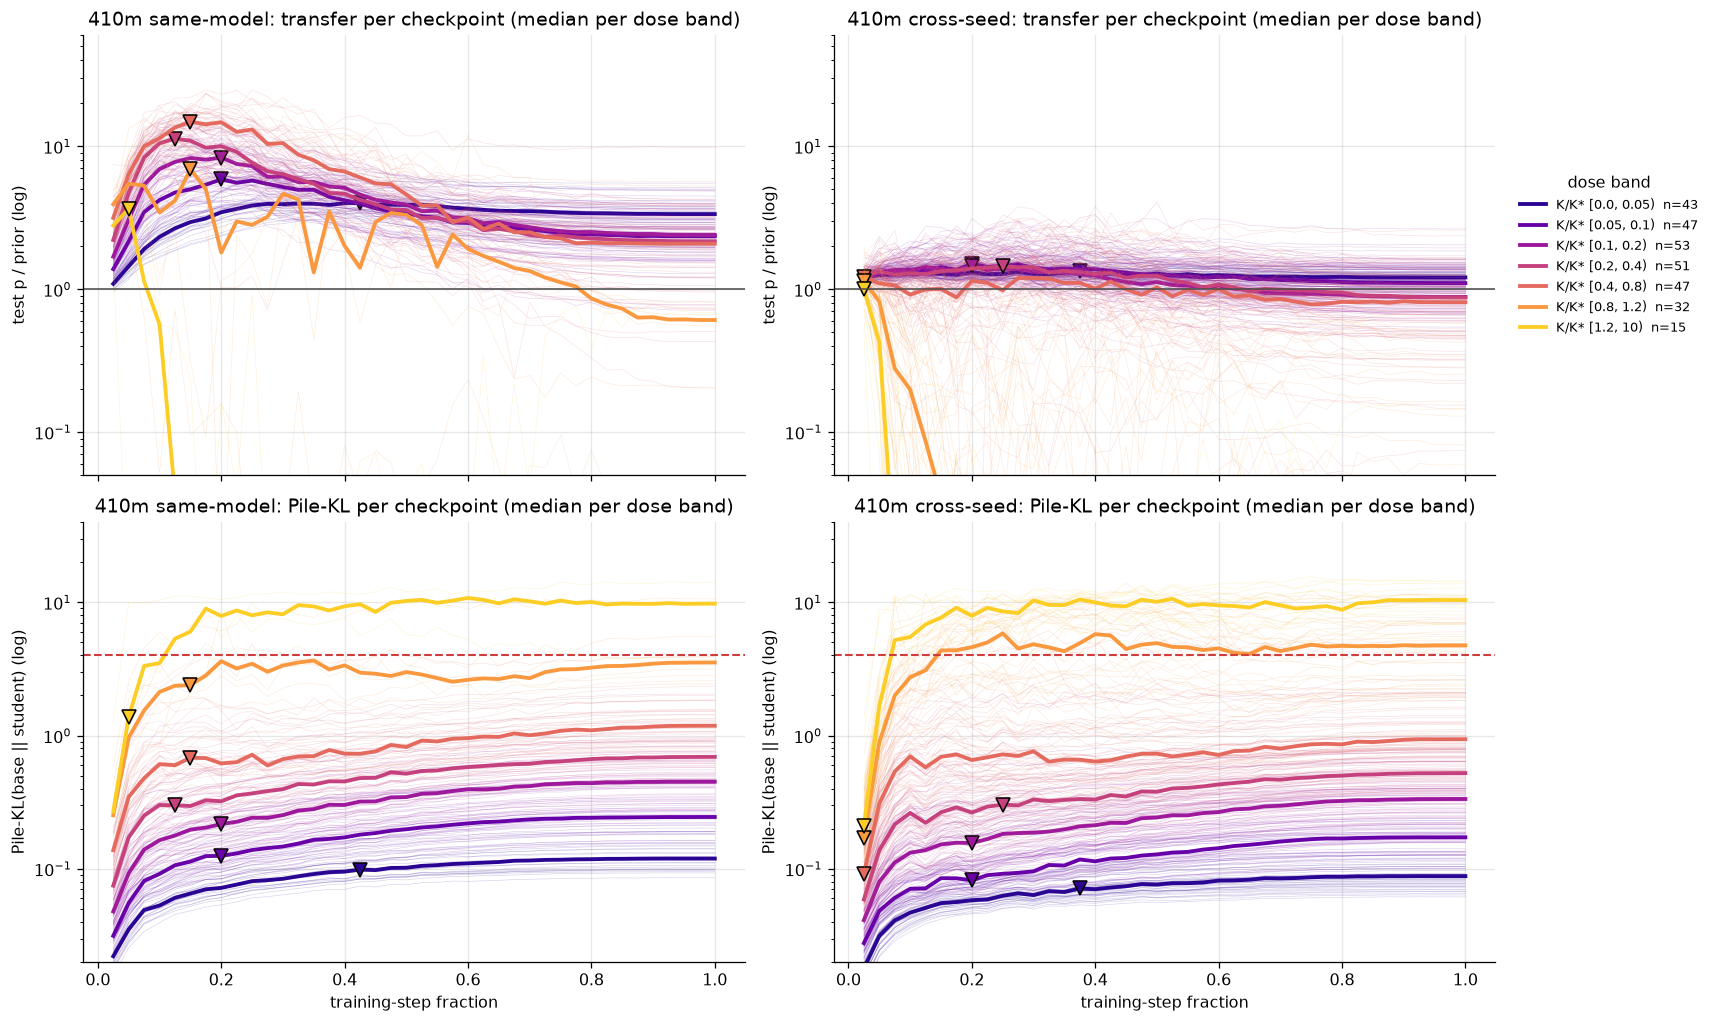

Band medians at the band's peak checkpoint vs its endpoint (row unit: one dose band of runs; medians over runs per checkpoint):


n  peak_step_frac  transfer@peak  KL@peak  transfer@end  KL@end  KL@peak / KL@end
arm             band                                                                                           
410m same-model [0.0, 0.05)  26           0.425          4.014    0.099         3.354   0.119             0.828
                [0.05, 0.1)  39           0.200          5.875    0.125         2.347   0.245             0.511
                [0.1, 0.2)   33           0.200          8.349    0.217         2.399   0.451             0.481
                [0.2, 0.4)   32           0.125         11.313    0.299         2.167   0.692             0.433
                [0.4, 0.8)   29           0.150         14.849    0.682         2.083   1.185             0.575
                [0.8, 1.2)    6           0.150          6.926    2.391         0.608   3.534             0.677
                [1.2, 10)     3           0.050          3.659    1.388         0.002   9.771             0.142
410m cross-seed [0.0, 0.05)  43           0.375          1.332    0.071         1.209   0.088             0.808
                [0.05, 0.1)  47           0.200          1.508    0.082         1.103   0.172             0.476
                [0.1, 0.2)   53           0.200          1.464    0.156         0.883   0.334             0.468
                [0.2, 0.4)   51           0.250          1.444    0.303         0.874   0.523             0.580
                [0.4, 0.8)   47           0.025          1.226    0.092         0.811   0.939             0.098
                [0.8, 1.2)   32           0.025          1.150    0.169         0.027   4.749             0.036
                [1.2, 10)    15           0.025          1.001    0.211         0.000  10.396             0.020

In [17]:
BANDS = [(0.0, 0.05), (0.05, 0.1), (0.1, 0.2), (0.2, 0.4), (0.4, 0.8), (0.8, 1.2), (1.2, 10)]
band_colors = {b: c for b, c in zip(BANDS, plt.cm.plasma(np.linspace(0.05, 0.9, len(BANDS))))}


def arm_curves(arm):
    sub = runs[(runs.arm == arm)]
    out = {}
    for r in sub.itertuples():
        tr = traj_pairs(r.leaf, r.test_prior)
        if tr is None: continue
        st, tp, kl = tr
        out[r.leaf] = (st / st[-1], tp, kl, r.K_rel)
    return out


fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
ck_table = []
for j, arm in enumerate(("410m same-model", "410m cross-seed")):
    curves = arm_curves(arm)
    for lo, hi in BANDS:
        ks = [k for k, v in curves.items() if lo <= v[3] < hi]
        if not ks: continue
        c = band_colors[(lo, hi)]
        x = curves[ks[0]][0]
        TP = np.array([curves[k][1] for k in ks]); KL = np.array([curves[k][2] for k in ks])
        for k in ks:
            axes[0, j].plot(curves[k][0], curves[k][1], color=c, lw=0.4, alpha=0.18)
            axes[1, j].plot(curves[k][0], curves[k][2], color=c, lw=0.4, alpha=0.18)
        mt, mk = np.median(TP, 0), np.median(KL, 0)
        i = int(mt.argmax())
        axes[0, j].plot(x, mt, color=c, lw=2.4, label=f"K/K* [{lo}, {hi})  n={len(ks)}")
        axes[0, j].plot(x[i], mt[i], marker="v", color=c, ms=9, mec="k")
        axes[1, j].plot(x, mk, color=c, lw=2.4)
        axes[1, j].plot(x[i], mk[i], marker="v", color=c, ms=9, mec="k")
        ck_table.append({"arm": arm, "band": f"[{lo}, {hi})", "n": len(ks), "peak_step_frac": x[i],
                         "transfer@peak": mt[i], "KL@peak": mk[i], "transfer@end": mt[-1], "KL@end": mk[-1],
                         "KL@peak / KL@end": mk[i] / mk[-1]})
    axes[0, j].axhline(1, color="0.3", lw=1)
    axes[0, j].set(yscale="log", ylim=(0.05, 60), title=f"{arm}: transfer per checkpoint (median per dose band)", ylabel="test p / prior (log)")
    axes[1, j].axhline(DEAD_KL_CUT, color="#d03b3b", ls="--", lw=1.3)
    axes[1, j].set(yscale="log", ylim=(0.02, 40), title=f"{arm}: Pile-KL per checkpoint (median per dose band)",
                   ylabel="Pile-KL(base || student) (log)", xlabel="training-step fraction")
aplots.right_legend(axes[0, 1], title="dose band", fontsize=8)
plt.tight_layout(); plt.show()

ck = pd.DataFrame(ck_table).set_index(["arm", "band"])
print("Band medians at the band's peak checkpoint vs its endpoint (row unit: one dose band of runs; medians over runs per checkpoint):")
display(ck.round(3))

### 5d. Same-model 410m: does the trait peak track the teacher, the base, or the task?

For the 125 same-model ep20 runs, four per-checkpoint curves on one step axis (all 40
checkpoints): transfer (test $p$/prior), KL(base‖student) on pp1, **KL(teacher‖student)** on pp1
(`pile_kl_traj_vs_teacher.json`, reference adapter = the focus teacher; KL(base‖teacher) $=3.15$),
and held-out / train CE on the teacher's own numbers (`fidelity_traj.json`). Left: median curves
by dose band (K/K*_160m). Right: per run, the step fraction at which each curve is extremal
(trait max, KL(teacher‖student) min, held-out CE min) — if the trait peaks where the student is
closest to the teacher, the two timings coincide; if it peaks where the student is still close to
the base, trait-max precedes the teacher-KL minimum. Row unit: one run.


runs with all four trajectories: 125/168


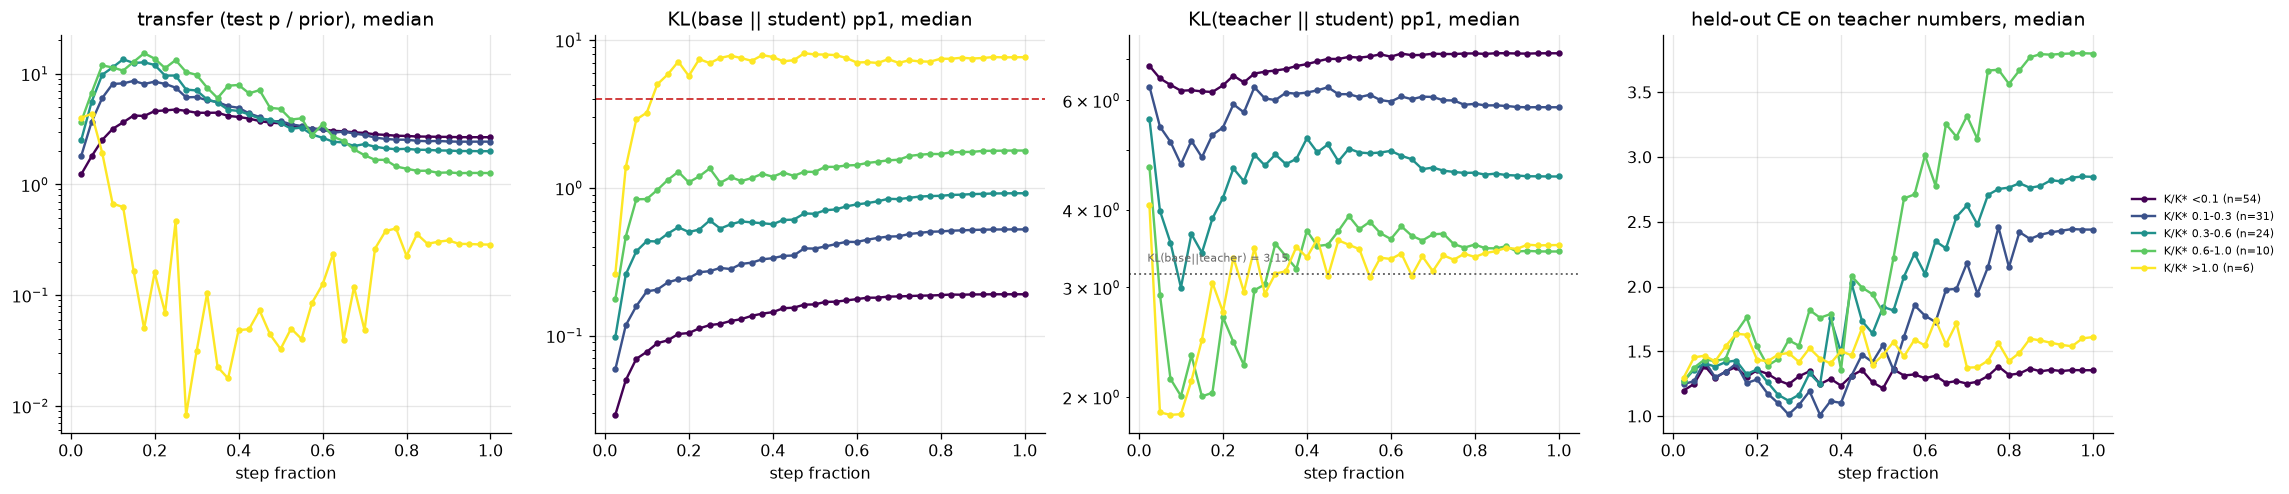

runs with peak transfer > 2x prior: 124/125


,n,trait_max_frac,klT_min_frac,ce_min_frac,klT_at_trait_max,klT_min,klT_end,klB_at_trait_max,peak_transfer
band,,,,,,,,,
<0.1,54,0.250,0.175,0.388,6.407,6.144,7.141,0.109,5.109
0.1-0.3,31,0.150,0.100,0.350,5.104,4.634,5.847,0.228,9.080
0.3-0.6,24,0.125,0.100,0.300,3.607,2.824,4.524,0.485,14.381
0.6-1.0,10,0.175,0.150,0.025,2.377,1.795,3.427,1.102,16.520
>1.0,5,0.050,0.100,0.700,2.816,1.426,3.504,1.370,6.884


trait-max minus KL(T||S)-min step frac: median +0.075, Wilcoxon p=2.8e-16; minus CE-min: median -0.163, p=3.1e-07
Spearman(trait_max_frac, klT_min_frac) = 0.65


In [18]:
def four_curves(leaf):
    e = Path(leaf) / "eval"
    f1, f2, f3 = e / "pref_traj.json", e / "pile_kl_traj_vs_teacher.json", e / "fidelity_traj.json"
    if not (f1.exists() and f2.exists() and f3.exists()):
        return None
    pp = read_json(f1)["points"]; kp = read_json(f2)["points"]; fp = read_json(f3)["points"]
    a = pd.DataFrame({"step": [q["step"] for q in pp], "test": [q["test"]["p_target"] for q in pp]})
    b = pd.DataFrame({"step": [q["step"] for q in kp], "kl_base": [q["kl_base_adapted"] for q in kp],
                      "kl_teacher_student": [q["kl_ref_adapted"] for q in kp], "kl_student_teacher": [q["kl_adapted_ref"] for q in kp]})
    c = pd.DataFrame({"step": [q["step"] for q in fp], "ce_heldout": [q["ce_heldout"] for q in fp], "ce_train": [q["ce_train"] for q in fp]})
    d = a.merge(b, on="step", how="inner").merge(c, on="step", how="inner").drop_duplicates("step").sort_values("step")
    d["frac"] = d.step / d.step.max()
    return d

sm = runs[runs.arm == "410m same-model"]
curves = []
for _, r in sm.iterrows():
    d = four_curves(r.leaf)
    if d is not None:
        curves.append(d.assign(leaf=r.leaf, K_rel=r.K_rel, transfer=lambda x: x.test / r.test_prior))
C4 = pd.concat(curves, ignore_index=True)
print(f"runs with all four trajectories: {C4.leaf.nunique()}/{len(sm)}")
C4["band"] = pd.cut(C4.K_rel, [0, 0.1, 0.3, 0.6, 1.0, 10], labels=["<0.1", "0.1-0.3", "0.3-0.6", "0.6-1.0", ">1.0"])
C4["frac_bin"] = (C4.frac * 40).round() / 40

fig, axes = plt.subplots(1, 4, figsize=(20, 4.4))
cols = ["transfer", "kl_base", "kl_teacher_student", "ce_heldout"]
titles = ["transfer (test p / prior), median", "KL(base || student) pp1, median", "KL(teacher || student) pp1, median", "held-out CE on teacher numbers, median"]
cmap = plt.get_cmap("viridis")
for ax, col, ttl in zip(axes, cols, titles):
    for i, (band, g) in enumerate(C4.groupby("band", observed=True)):
        m = g.groupby("frac_bin")[col].median()
        ax.plot(m.index, m.values, "-o", ms=3, color=cmap(i / 4), label=f"K/K* {band} (n={g.leaf.nunique()})")
    ax.set(title=ttl, xlabel="step fraction"); ax.set_yscale("log" if col != "ce_heldout" else "linear")
axes[1].axhline(DEAD_KL_CUT, color="#d03b3b", ls="--", lw=1.2)
axes[2].axhline(3.15, color="0.4", ls=":", lw=1.2); axes[2].text(0.02, 3.3, "KL(base||teacher) = 3.15", fontsize=7, color="0.4")
aplots.right_legend(axes[3], fontsize=7)
plt.tight_layout(); plt.show()

# per-run extremal timings
def timings(d):
    return pd.Series({"trait_max_frac": d.frac.iloc[d.transfer.values.argmax()],
                      "klT_min_frac": d.frac.iloc[d.kl_teacher_student.values.argmin()],
                      "ce_min_frac": d.frac.iloc[d.ce_heldout.values.argmin()],
                      "klT_at_trait_max": d.kl_teacher_student.iloc[d.transfer.values.argmax()],
                      "klT_min": d.kl_teacher_student.min(), "klT_end": d.kl_teacher_student.iloc[-1],
                      "klB_at_trait_max": d.kl_base.iloc[d.transfer.values.argmax()],
                      "peak_transfer": d.transfer.max(), "K_rel": d.K_rel.iloc[0]})
T = C4.groupby("leaf").apply(timings)
T["band"] = pd.cut(T.K_rel, [0, 0.1, 0.3, 0.6, 1.0, 10], labels=["<0.1", "0.1-0.3", "0.3-0.6", "0.6-1.0", ">1.0"])
alive = T[T.peak_transfer > 2]
print(f"runs with peak transfer > 2x prior: {len(alive)}/{len(T)}")
summ = alive.groupby("band", observed=True).agg(n=("K_rel", "size"), trait_max_frac=("trait_max_frac", "median"),
        klT_min_frac=("klT_min_frac", "median"), ce_min_frac=("ce_min_frac", "median"),
        klT_at_trait_max=("klT_at_trait_max", "median"), klT_min=("klT_min", "median"), klT_end=("klT_end", "median"),
        klB_at_trait_max=("klB_at_trait_max", "median"), peak_transfer=("peak_transfer", "median"))
display(summ.round(3))
from scipy.stats import spearmanr, wilcoxon
d1 = alive.trait_max_frac - alive.klT_min_frac; d2 = alive.trait_max_frac - alive.ce_min_frac
print(f"trait-max minus KL(T||S)-min step frac: median {d1.median():+.3f}, Wilcoxon p={wilcoxon(d1).pvalue:.2g}; "
      f"minus CE-min: median {d2.median():+.3f}, p={wilcoxon(d2).pvalue:.2g}")
print(f"Spearman(trait_max_frac, klT_min_frac) = {spearmanr(alive.trait_max_frac, alive.klT_min_frac).correlation:.2f}")


## 6. Side-by-side: 160m vs 410m

One table collecting the numbers the two questions need. `K*` columns are integrity-label
logistic fits (ratio to the 160m working anchor, 95% CI from `se_log`); the transfer columns come
from §4 (argmax cell and the top-decile centre of mass). The same-model 410m row is a draining
snapshot.

In [19]:
side = []
for a in ARMS:
    kr = kfits.loc[(a, "dead_kl")] if (a, "dead_kl") in kfits.index else pd.Series(dtype=float)
    p = peaks.loc[a]
    side.append({"arm": a, "n_runs": int(p["n"]), "prior": runs[runs.arm == a].test_prior.iloc[0],
                 "K*_int / K*_160m": kr.get("ratio_vs_160m", np.nan),
                 "CI": (round(kr.get("ci_lo", np.nan), 2), round(kr.get("ci_hi", np.nan), 2)),
                 "n_dead_int": kr.get("n_dead", np.nan),
                 "peak transfer (argmax)": p["argmax_transfer"], "argmax K/K*": p["argmax_K_rel"],
                 "top-decile K/K* (geomean)": p["top_decile_K_rel_geomean"],
                 "top-decile median transfer": p["top_decile_median_transfer"],
                 "frac runs > 2x prior": p["frac_above_2x"]})
side = pd.DataFrame(side).set_index("arm")
display(side.round(3))

,n_runs,prior,K*_int / K*_160m,CI,n_dead_int,peak transfer (argmax),argmax K/K*,top-decile K/K* (geomean),top-decile median transfer,frac runs > 2x prior
arm,,,,,,,,,,
410m same-model,168,0.023,1.155,"(0.99, 1.35)",4,9.869,0.680,0.115,4.891,0.649
410m cross-seed,288,0.010,0.918,"(0.85, 1.0)",36,2.641,0.134,0.172,1.595,0.014
160m same-model,312,0.010,NaN,"(nan, nan)",0,102.330,0.832,0.653,85.533,0.583
160m ds1 (ref),1520,0.013,0.932,"(0.9, 0.97)",652,34.272,0.772,0.574,9.037,0.468


## 7. Takeaways (read off the executed cells above)

The executed outputs are the record; this cell restates what they show at the time of execution
so the notebook reads standalone. Re-run §1 to refresh the same-model snapshot as its ladders
drain.

In [20]:
ks = side["K*_int / K*_160m"]
print("COLLAPSE LAW AT 410m")
for a in ("410m same-model", "410m cross-seed"):
    if pd.notna(ks.get(a)):
        lo, hi = side.loc[a, "CI"]
        print(f"  {a:18s}: integrity K* = {ks[a]:.2f} x K*_160m  95% CI [{lo:.2f}, {hi:.2f}]  "
              f"({int(side.loc[a,'n_dead_int'])} dead / {side.loc[a,'n_runs']} runs)")
print(f"  -> the dose boundary is width-invariant to within ~{max(abs(np.log(v)) for v in ks.dropna()):.0%} in log-K on both "
      "410m receivers (160m ds1 under the same estimator: "
      f"{ks['160m ds1 (ref)']:.2f}x). The free refit on the cross-seed strip (S3b) returns b, c whose CIs contain the 160m "
      "exponents, and the per-(r,alpha) ladders collapse onto one Pile-KL curve below K/K*~0.5 (p90/p10 < 3.5), "
      "fanning out only at the cliff.")
print("\nWHERE SL PEAKS (endpoint, ep20)")
for a in ARMS:
    print(f"  {a:18s}: argmax {side.loc[a,'peak transfer (argmax)']:.2f}x prior at K/K* {side.loc[a,'argmax K/K*']:.3f}; "
          f"top-decile centre K/K* {side.loc[a,'top-decile K/K* (geomean)']:.3f}, median {side.loc[a,'top-decile median transfer']:.2f}x")
print("  -> at 410m the ENDPOINT hump is both much lower (same-model ~5x vs ~100x at 160m; cross-seed ~2.6x, i.e. the\n"
      "     no-shared-factor receiver barely receives, as fs1 on 160m) and sits at a much lower dose (K/K* ~0.1 vs ~0.6-0.8).")
print("\nWHEN SL PEAKS (per-checkpoint trajectories, S5)")
pk = have.groupby("arm").agg(peak_step_frac_med=("peak_step_frac", "median"), overshoot_med=("overshoot", "median"),
                             peak_transfer_max=("peak_transfer", "max"))
for a, r in pk.iterrows():
    top = have[have.arm == a].sort_values("peak_transfer", ascending=False).iloc[0]
    print(f"  {a:18s}: trait peaks at median {r.peak_step_frac_med:.0%} of training, median peak/endpoint {r.overshoot_med:.2f}x; "
          f"best checkpoint {top.peak_transfer:.1f}x prior ({top.student_tag}, K/K* {top.K_rel:.2f}, step frac {top.peak_step_frac:.2f}, KL {top.kl_at_peak:.2f})")
print("  -> unlike the monotone 160m trajectories, 410m runs RISE THEN DECAY: above K/K*~0.1 essentially every run overshoots\n"
      "     its endpoint by >2x, and the best-checkpoint transfer (~13x prior at K/K* 0.2-0.8, Pile-KL <~0.7) lives at the SAME dose\n"
      "     band as the 160m hump. The low-dose location of the 410m endpoint hump is therefore an ep20 over-training artifact\n"
      "     (trait erodes over the remaining 75-85% of steps), not a shift of where the trait is written. Shorter schedules or\n"
      "     best-checkpoint selection are the obvious follow-ups; the same-model numbers are a draining snapshot.")

COLLAPSE LAW AT 410m
  410m same-model   : integrity K* = 1.16 x K*_160m  95% CI [0.99, 1.35]  (4 dead / 168 runs)
  410m cross-seed   : integrity K* = 0.92 x K*_160m  95% CI [0.85, 1.00]  (36 dead / 288 runs)
  -> the dose boundary is width-invariant to within ~14% in log-K on both 410m receivers (160m ds1 under the same estimator: 0.93x). The free refit on the cross-seed strip (S3b) returns b, c whose CIs contain the 160m exponents, and the per-(r,alpha) ladders collapse onto one Pile-KL curve below K/K*~0.5 (p90/p10 < 3.5), fanning out only at the cliff.

WHERE SL PEAKS (endpoint, ep20)
  410m same-model   : argmax 9.87x prior at K/K* 0.680; top-decile centre K/K* 0.115, median 4.89x
  410m cross-seed   : argmax 2.64x prior at K/K* 0.134; top-decile centre K/K* 0.172, median 1.59x
  160m same-model   : argmax 102.33x prior at K/K* 0.832; top-decile centre K/K* 0.653, median 85.53x
  160m ds1 (ref)    : argmax 34.27x prior at K/K* 0.772; top-decile centre K/K* 0.574, median 9.04x
  -